In [113]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import FunctionTransformer
from sklearn.metrics import silhouette_samples
from sklearn.metrics import silhouette_score



In [114]:
# read in the data from csv file
df = pd.read_csv('C:/Users/Mert/OneDrive/Desktop/FoPra/data/cleaned data/combined_OES_data.csv')

# Find rows where 'ID 1' contains an underscore
mask = df['ID 1'].str.contains('_')

# Swap 'ID 1' and 'Grade' values in these rows
df.loc[mask, ['ID 1', 'Grade']] = df.loc[mask, ['Grade', 'ID 1']].values

# FIXME?: keep lesser and greater?
# Identifying columns that contain 'lesser' or 'greater' in their names
columns_to_drop = [col for col in df.columns if 'lesser' in col or 'greater' in col or 'Unnamed' in col]

# FIXME?: keep ID 1 where typ of steel is present for future analysis 
# Adding specific columns to the list
additional_columns = ['Program Name', 'Mode', 'Burn', 'ID 1', 'ID 2', 'ID 3', 'Date']
columns_to_drop.extend(additional_columns)

# Ensuring only columns present in df are attempted to be dropped
columns_to_drop = [col for col in columns_to_drop if col in df.columns]

# Dropping these columns from the DataFrame
df = df.drop(columns=columns_to_drop)

# reduce the number of rows by removing every row without proper grade
df = df[df['Grade'].str.contains('_')]

# Define the condition for moving rows
condition = (df['Fe'] < 97.0) | (df['S'] > 0.09) | (df['Al'] > 0.075) | (df['Pb'] > 0.06)

# Create df_out with rows that match the condition
df_out = df[condition].copy()

# Add the 'Measuring error' column set to True
df_out['Measuring error'] = True

# Remove the rows from the original df
df = df[~condition]

# Test Aufbereitung


In [115]:
# Lies die Daten aus der csv Datei ein
df_test = pd.read_csv('C:/Users/Mert/OneDrive/Desktop/FoPra/data/cleaned data/combined_OES_data.csv')

# Find rows where 'ID 1' contains an underscore
mask = df_test['ID 1'].str.contains('_')

# Swap 'ID 1' and 'Grade' values in these rows
df_test.loc[mask, ['ID 1', 'Grade']] = df_test.loc[mask, ['Grade', 'ID 1']].values

# Droppe alle Spalten die 'lesser', 'greater' oder 'Unnamed' im Namen haben
columns_to_drop_all = [col for col in df_test.columns if 'lesser' in col or 'greater' in col or 'Unnamed' in col]

# Entferne die Spalten aus der Liste
df_test = df_test.drop(columns=columns_to_drop_all)

# Finde die Werte in 'Grade' für Zeilen, die 'St' in 'ID 1' enthalten
grades_with_st = df_test[df_test['ID 1'].str.contains('St')]['Grade']

# Zeilen filtern, die entweder 'St' in 'ID 1' enthalten oder denselben 'Grade' Wert haben
df_test = df_test[df_test['ID 1'].str.contains('St') | df_test['Grade'].isin(grades_with_st)]

# Entfernen der Spalten 'Program Name', 'Mode', 'Burn', 'ID 2', 'ID 3', 'Date'
df_test = df_test.drop(columns=['Program Name', 'Mode', 'Burn', 'ID 2', 'ID 3', 'Date'])

# Alle 'St37' in 'ID 1' zu 'St 37' ändern
df_test['ID 1'] = df_test['ID 1'].replace('St37', 'St 37')

# Gruppieren der Daten nach 'Grade' und 'ID 1' und Berechnung des Mittelwerts
df_test = df_test.groupby(['Grade', 'ID 1']).mean()

# reset the index
df_test = df_test.reset_index()

# reduce the number of rows by removing every row without proper grade
df_test = df_test[df_test['Grade'].str.contains('_')]

# entferne Duplikate
df_test = df_test.drop_duplicates()

df_test

,Grade,ID 1,Fe,C,Si,Mn,P,S,Cr,Mo,...,Ti,V,W,Pb,Sn,B,Ca,Zr,As,Bi
0,20_21_1,St 48,0.0,0.0331,0.204,0.701,0.0291,0.0295,0.0075,0.0051,...,0.0010,0.0020,0.04,0.0150,0.0080,0.001,0.0010,0.002,0.0507,0.0114
1,20_23_1,St 48,0.0,0.1620,0.130,0.720,0.0217,0.0411,0.0052,0.0041,...,0.0032,0.0018,0.04,0.0347,0.0122,0.001,0.0013,0.002,0.0629,0.0108
2,20_28_1,St 48,0.0,0.1440,0.265,0.600,0.0186,0.0261,0.0050,0.0049,...,0.0012,0.0018,0.04,0.0150,0.0191,0.001,0.0010,0.002,0.0638,0.0100
3,20_31_1,St 48,0.0,0.2640,0.274,0.627,0.0129,0.0312,0.0050,0.0049,...,0.0012,0.0023,0.04,0.0150,0.0089,0.001,0.0010,0.002,0.0353,0.0100
4,20_32_1,St 48,0.0,0.2550,0.288,0.643,0.0114,0.0577,0.0050,0.0040,...,0.0014,0.0023,0.04,0.0150,0.0106,0.001,0.0010,0.002,0.0444,0.0103
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
257,S1_41_3_2,St 48-Th,0.0,0.2370,0.005,0.553,0.0489,0.0401,0.0050,0.0044,...,0.0010,0.0022,0.04,0.0150,0.0023,0.001,0.0010,0.002,0.0071,0.0171
258,S2_11_1_2,St 48-BK?,0.0,0.2250,0.005,0.429,0.0100,0.0305,0.0050,0.0042,...,0.0010,0.0015,0.04,0.0150,0.0081,0.001,0.0010,0.002,0.0311,0.0100
259,S2_11_2_2,St37-BK?,0.0,0.1880,0.005,0.421,0.0101,0.0265,0.0050,0.0041,...,0.0010,0.0017,0.04,0.0150,0.0082,0.001,0.0010,0.002,0.0286,0.0128
260,S2_11_2_2,St48-BK?,0.0,0.1880,0.005,0.421,0.0101,0.0265,0.0050,0.0041,...,0.0010,0.0017,0.04,0.0150,0.0082,0.001,0.0010,0.002,0.0286,0.0128


# TestVorbereitung

In [116]:
df_modified = df_test.copy()

# Wähle alle Spalten aus, die nicht 'Grade', 'ID 1' oder 'Fe' sind
cols_to_sum = df_modified.columns.difference(['Grade', 'ID 1', 'Fe'])

# Berechne die Summe der ausgewählten Spalten für jede Zeile
df_modified['sum'] = df_modified[cols_to_sum].sum(axis=1)

# Schreibe 100 minus den berechneten Summenwert in 'Fe'
df_modified['Fe'] = 100 - df_modified['sum']

# Entferne die Hilfsspalte 'sum', falls sie nicht benötigt wird
df_modified.drop(columns=['sum'], inplace=True)

# Überschreibe df_test mit dem modifizierten DataFrame
df_test = df_modified.copy()

# entferne die Spalten 'Grade' und 'ID 1'
df_test1 = df_test.drop(columns=['Grade', 'ID 1'])

# save test data as csv
df_test.to_csv('C:/Users/Mert/OneDrive/Desktop/FoPra/data/cleaned data/test_data.csv', index=False)

# Überprüfe das Ergebnis
df_test

,Grade,ID 1,Fe,C,Si,Mn,P,S,Cr,Mo,...,Ti,V,W,Pb,Sn,B,Ca,Zr,As,Bi
0,20_21_1,St 48,98.7049,0.0331,0.204,0.701,0.0291,0.0295,0.0075,0.0051,...,0.0010,0.0020,0.04,0.0150,0.0080,0.001,0.0010,0.002,0.0507,0.0114
1,20_23_1,St 48,98.5637,0.1620,0.130,0.720,0.0217,0.0411,0.0052,0.0041,...,0.0032,0.0018,0.04,0.0347,0.0122,0.001,0.0013,0.002,0.0629,0.0108
2,20_28_1,St 48,98.5843,0.1440,0.265,0.600,0.0186,0.0261,0.0050,0.0049,...,0.0012,0.0018,0.04,0.0150,0.0191,0.001,0.0010,0.002,0.0638,0.0100
3,20_31_1,St 48,98.4618,0.2640,0.274,0.627,0.0129,0.0312,0.0050,0.0049,...,0.0012,0.0023,0.04,0.0150,0.0089,0.001,0.0010,0.002,0.0353,0.0100
4,20_32_1,St 48,98.4568,0.2550,0.288,0.643,0.0114,0.0577,0.0050,0.0040,...,0.0014,0.0023,0.04,0.0150,0.0106,0.001,0.0010,0.002,0.0444,0.0103
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
257,S1_41_3_2,St 48-Th,98.9310,0.2370,0.005,0.553,0.0489,0.0401,0.0050,0.0044,...,0.0010,0.0022,0.04,0.0150,0.0023,0.001,0.0010,0.002,0.0071,0.0171
258,S2_11_1_2,St 48-BK?,98.9597,0.2250,0.005,0.429,0.0100,0.0305,0.0050,0.0042,...,0.0010,0.0015,0.04,0.0150,0.0081,0.001,0.0010,0.002,0.0311,0.0100
259,S2_11_2_2,St37-BK?,99.0097,0.1880,0.005,0.421,0.0101,0.0265,0.0050,0.0041,...,0.0010,0.0017,0.04,0.0150,0.0082,0.001,0.0010,0.002,0.0286,0.0128
260,S2_11_2_2,St48-BK?,99.0097,0.1880,0.005,0.421,0.0101,0.0265,0.0050,0.0041,...,0.0010,0.0017,0.04,0.0150,0.0082,0.001,0.0010,0.002,0.0286,0.0128


# Entfernung von Ausreißern

In [117]:
df.describe()

,Fe,C,Si,Mn,P,S,Cr,Mo,Ni,Al,...,Ti,V,W,Pb,Sn,B,Ca,Zr,As,Bi
count,2874.000000,2874.000000,2874.000000,2874.000000,2874.000000,2874.000000,2874.000000,2874.000000,2874.000000,2874.000000,...,2874.000000,2874.000000,2874.000000,2874.000000,2874.000000,2874.000000,2874.000000,2874.000000,2874.000000,2874.000000
mean,98.504036,0.187415,0.243858,0.603558,0.024926,0.038063,0.021933,0.004145,0.051400,0.005750,...,0.001655,0.002364,0.040129,0.015414,0.014616,0.001952,0.001273,0.002388,0.039108,0.017430
std,0.439620,0.083674,0.242040,0.158444,0.014630,0.013587,0.039899,0.001657,0.031861,0.008926,...,0.000964,0.001425,0.003745,0.003306,0.009484,0.000515,0.000856,0.000881,0.016881,0.008046
min,97.000000,0.003000,0.005000,0.050900,0.003000,0.002000,0.005000,0.003000,0.005000,0.002000,...,0.001000,0.001000,0.040000,0.015000,0.002000,0.001000,0.000000,0.002000,0.000000,0.000000
25%,98.300000,0.125000,0.013200,0.493250,0.015025,0.029225,0.007000,0.003000,0.034125,0.002000,...,0.001200,0.001800,0.040000,0.015000,0.007800,0.001600,0.001000,0.002000,0.027500,0.010000
50%,98.500000,0.204000,0.227000,0.601000,0.023000,0.037550,0.012300,0.003400,0.046300,0.002400,...,0.001500,0.002200,0.040000,0.015000,0.013700,0.001900,0.001100,0.002000,0.040750,0.016000
75%,98.800000,0.248000,0.276000,0.694750,0.031475,0.045875,0.023700,0.004800,0.055300,0.004500,...,0.001800,0.002600,0.040000,0.015000,0.018700,0.002200,0.001300,0.002000,0.050400,0.022900
max,99.500000,0.651000,1.420000,1.240000,0.170000,0.089200,0.442000,0.014700,0.287000,0.060900,...,0.017900,0.037100,0.195000,0.058600,0.067700,0.010900,0.010000,0.007100,0.125000,0.095700


In [118]:
def find_outliers(series):
    Q1 = series.quantile(0.05)
    Q3 = series.quantile(0.95)
    IQR = Q3 - Q1
    return (series < (Q1 - 1.5 * IQR)) | (series > (Q3 + 1.5 * IQR))


# Apply the function to each column of df, except 'Grade'
outliers = df.drop(columns=['Grade']).apply(find_outliers)

# Any row with at least one outlier in the selected columns
rows_with_outliers = outliers.any(axis=1)

# Select rows containing outliers
new_outliers = df[rows_with_outliers].copy()

# Add the 'outlier' column set to True
new_outliers['outlier'] = True

# Append these rows to the existing df_out
df_out = pd.concat([df_out, new_outliers])

# Remove these rows from the original df
df = df[~rows_with_outliers]

print(new_outliers.describe())
df.describe()

               Fe           C          Si          Mn           P           S  \
count  210.000000  210.000000  210.000000  210.000000  210.000000  210.000000   
mean    98.229048    0.160288    0.347612    0.683076    0.032734    0.040130   
std      0.633864    0.092964    0.317573    0.253896    0.032091    0.016703   
min     97.000000    0.003000    0.005000    0.101000    0.003000    0.002000   
25%     97.800000    0.089200    0.061225    0.507000    0.014800    0.032200   
50%     98.200000    0.163500    0.278000    0.642000    0.022600    0.039700   
75%     98.800000    0.198750    0.503750    0.889000    0.036425    0.049375   
max     99.500000    0.651000    1.420000    1.240000    0.170000    0.089200   

               Cr          Mo          Ni          Al  ...          Ti  \
count  210.000000  210.000000  210.000000  210.000000  ...  210.000000   
mean     0.073683    0.004421    0.062170    0.017388  ...    0.002536   
std      0.125866    0.002306    0.060983    0.0

,Fe,C,Si,Mn,P,S,Cr,Mo,Ni,Al,...,Ti,V,W,Pb,Sn,B,Ca,Zr,As,Bi
count,2664.000000,2664.000000,2664.000000,2664.000000,2664.000000,2664.000000,2664.000000,2664.000000,2664.000000,2664.000000,...,2664.000000,2664.000000,2.664000e+03,2.664000e+03,2664.000000,2664.000000,2664.000000,2664.000000,2664.000000,2664.000000
mean,98.525713,0.189553,0.235680,0.597290,0.024310,0.037900,0.017854,0.004124,0.050551,0.004832,...,0.001586,0.002266,4.000000e-02,1.500000e-02,0.014689,0.001941,0.001172,0.002396,0.039367,0.017429
std,0.412965,0.082539,0.233178,0.146585,0.012037,0.013301,0.015693,0.001593,0.028168,0.007118,...,0.000658,0.000604,1.388039e-17,3.470098e-18,0.009596,0.000477,0.000276,0.000888,0.016321,0.007606
min,97.300000,0.003000,0.005000,0.050900,0.003000,0.002000,0.005000,0.003000,0.008600,0.002000,...,0.001000,0.001000,4.000000e-02,1.500000e-02,0.002000,0.001000,0.000000,0.002000,0.000000,0.000000
25%,98.300000,0.126000,0.011200,0.492000,0.015100,0.029200,0.007200,0.003000,0.034600,0.002000,...,0.001200,0.001875,4.000000e-02,1.500000e-02,0.007800,0.001600,0.001000,0.002000,0.027900,0.010000
50%,98.500000,0.207000,0.225000,0.599000,0.023000,0.037200,0.012200,0.003400,0.046800,0.002200,...,0.001400,0.002200,4.000000e-02,1.500000e-02,0.013600,0.001900,0.001100,0.002000,0.041100,0.016200
75%,98.800000,0.249000,0.270000,0.689000,0.031300,0.045700,0.022900,0.004800,0.055100,0.004000,...,0.001700,0.002600,4.000000e-02,1.500000e-02,0.018500,0.002200,0.001200,0.002000,0.050400,0.022800
max,99.500000,0.475000,1.320000,1.040000,0.090000,0.087500,0.110000,0.013700,0.199000,0.055600,...,0.006100,0.005900,4.000000e-02,1.500000e-02,0.067700,0.004200,0.003200,0.007100,0.125000,0.052600


# Duplikate werden entfern

In [119]:
# Remove duplicates
df = df.drop_duplicates()

df.describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99])

,Fe,C,Si,Mn,P,S,Cr,Mo,Ni,Al,...,Ti,V,W,Pb,Sn,B,Ca,Zr,As,Bi
count,2160.000000,2160.000000,2160.000000,2160.000000,2160.000000,2160.000000,2160.000000,2160.000000,2160.000000,2160.000000,...,2160.000000,2160.000000,2.160000e+03,2.160000e+03,2160.000000,2160.000000,2160.000000,2160.000000,2160.000000,2160.000000
mean,98.527685,0.192527,0.231853,0.597188,0.024933,0.038230,0.017751,0.004115,0.049813,0.004606,...,0.001589,0.002275,4.000000e-02,1.500000e-02,0.014517,0.001958,0.001172,0.002398,0.040271,0.017725
std,0.402473,0.080610,0.221696,0.144899,0.012107,0.012990,0.015253,0.001593,0.026715,0.006418,...,0.000659,0.000586,6.940501e-18,3.470250e-18,0.008969,0.000471,0.000277,0.000889,0.015680,0.007679
min,97.300000,0.003000,0.005000,0.050900,0.003000,0.002000,0.005000,0.003000,0.008600,0.002000,...,0.001000,0.001000,4.000000e-02,1.500000e-02,0.002000,0.001000,0.000000,0.002000,0.000000,0.000000
1%,97.600000,0.025400,0.005000,0.284590,0.005359,0.012318,0.005000,0.003000,0.016159,0.002000,...,0.001000,0.001159,4.000000e-02,1.500000e-02,0.002000,0.001000,0.001000,0.002000,0.004000,0.010000
5%,97.800000,0.043000,0.005000,0.373000,0.008600,0.017995,0.005000,0.003000,0.022500,0.002000,...,0.001000,0.001500,4.000000e-02,1.500000e-02,0.002700,0.001300,0.001000,0.002000,0.013400,0.010000
25%,98.300000,0.132000,0.082450,0.494000,0.015900,0.029800,0.007500,0.003000,0.034600,0.002000,...,0.001200,0.001900,4.000000e-02,1.500000e-02,0.008000,0.001600,0.001000,0.002000,0.029875,0.010000
50%,98.500000,0.210000,0.225000,0.596000,0.023400,0.037600,0.012400,0.003400,0.046200,0.002300,...,0.001400,0.002200,4.000000e-02,1.500000e-02,0.014000,0.001900,0.001100,0.002000,0.041900,0.016700
75%,98.800000,0.250000,0.270000,0.690250,0.031800,0.045800,0.022625,0.004800,0.054925,0.004000,...,0.001700,0.002600,4.000000e-02,1.500000e-02,0.018400,0.002200,0.001200,0.002000,0.050800,0.023100
95%,99.200000,0.304000,0.844000,0.841000,0.046600,0.061500,0.051000,0.007000,0.108050,0.017205,...,0.003100,0.003300,4.000000e-02,1.500000e-02,0.030705,0.002800,0.001700,0.004600,0.064000,0.030905


In [120]:
df = df.groupby('Grade').mean()

# reset the index
df = df.reset_index()

# Drop the 'Grade' column
df = df.drop(columns=['Grade'])

df_out = df_out.reset_index()
df_out = df_out.drop(columns=['index'])

df.describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99])

,Fe,C,Si,Mn,P,S,Cr,Mo,Ni,Al,...,Ti,V,W,Pb,Sn,B,Ca,Zr,As,Bi
count,407.000000,407.000000,407.000000,407.000000,407.000000,407.000000,407.000000,407.000000,407.000000,407.000000,...,407.000000,407.000000,4.070000e+02,4.070000e+02,407.000000,407.000000,407.000000,407.000000,407.000000,407.000000
mean,98.528358,0.195502,0.235124,0.594342,0.024793,0.038842,0.016987,0.004119,0.049039,0.004819,...,0.001624,0.002267,4.000000e-02,1.500000e-02,0.014305,0.001957,0.001178,0.002397,0.039841,0.017518
std,0.401253,0.081389,0.221227,0.147132,0.012246,0.012922,0.014826,0.001587,0.026267,0.006438,...,0.000686,0.000598,6.947434e-18,3.451240e-18,0.008871,0.000437,0.000271,0.000646,0.015674,0.006822
min,97.300000,0.003933,0.005000,0.055800,0.003000,0.002000,0.005000,0.003000,0.011583,0.002000,...,0.001000,0.001000,4.000000e-02,1.500000e-02,0.002000,0.001000,0.000000,0.002000,0.000000,0.000000
1%,97.562400,0.019077,0.005000,0.266160,0.005357,0.004694,0.005000,0.003000,0.015918,0.002000,...,0.001000,0.001162,4.000000e-02,1.500000e-02,0.002000,0.001068,0.000060,0.002000,0.000240,0.000600
5%,97.800000,0.042159,0.005000,0.366933,0.008457,0.018400,0.005000,0.003000,0.021965,0.002000,...,0.001017,0.001524,4.000000e-02,1.500000e-02,0.002677,0.001288,0.001000,0.002000,0.012692,0.010000
25%,98.300000,0.136417,0.104417,0.494750,0.015875,0.030842,0.006992,0.003017,0.033775,0.002000,...,0.001200,0.001854,4.000000e-02,1.500000e-02,0.007775,0.001667,0.001017,0.002000,0.029192,0.011350
50%,98.483333,0.213333,0.226667,0.588500,0.023317,0.038617,0.012000,0.003600,0.045350,0.002640,...,0.001450,0.002167,4.000000e-02,1.500000e-02,0.013650,0.001933,0.001100,0.002017,0.041500,0.017000
75%,98.708333,0.252750,0.272583,0.692694,0.031233,0.047225,0.021125,0.004567,0.054875,0.004275,...,0.001733,0.002583,4.000000e-02,1.500000e-02,0.018117,0.002217,0.001250,0.002542,0.050900,0.021717
95%,99.200000,0.309400,0.843900,0.843933,0.046963,0.060663,0.048157,0.006747,0.092439,0.017362,...,0.003207,0.003245,4.000000e-02,1.500000e-02,0.030215,0.002785,0.001667,0.003731,0.063535,0.028872


# GMM (Gaussian Mixture Models Clustering Algorithm)

In [121]:
scaler = FunctionTransformer(np.log1p, validate=True)
df_scaled = scaler.fit_transform(df)

# Number of components (clusters) to fit
n_components = 8 # Adjustable parameter

# Create and fit the Gaussian Mixture Model
gmm = GaussianMixture(n_components=n_components, random_state=0)
gmm.fit(df_scaled)

# Predict the cluster for each data point
clusters = gmm.predict(df_scaled)

# count the number of points in each cluster
cluster_counts = np.bincount(clusters)

# sort clusters by size
cluster_counts = sorted(cluster_counts, reverse=True)
cluster_counts

[111, 90, 81, 45, 27, 27, 20, 6]

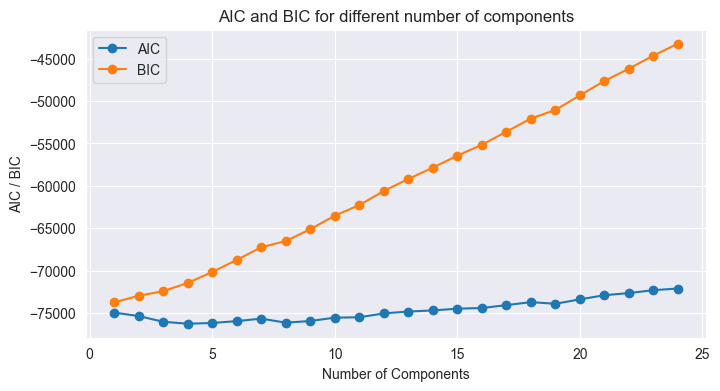

In [122]:
scaler = FunctionTransformer(np.log1p, validate=True)
df_scaled = scaler.fit_transform(df)

# Range of potential components
n_components_range = range(1, 25)  # Adjust this range as needed

# Lists to store AIC and BIC values
aics = []
bics = []

# Fit GMM models with different number of components
for n_components in n_components_range:
    gmm = GaussianMixture(n_components=n_components, random_state=0)
    gmm.fit(df_scaled)
    aics.append(gmm.aic(df_scaled))
    bics.append(gmm.bic(df_scaled))

# Plotting the AIC and BIC values
plt.figure(figsize=(8, 4))
plt.plot(n_components_range, aics, label='AIC', marker='o')
plt.plot(n_components_range, bics, label='BIC', marker='o')
plt.xlabel('Number of Components')
plt.ylabel('AIC / BIC')
plt.legend()
plt.title('AIC and BIC for different number of components')
plt.show()

Cluster Sizes: [53, 31, 30, 29, 27, 25, 21, 20, 19, 18, 17, 17, 16, 13, 12, 10, 9, 8, 7, 6, 6, 5, 4, 4]


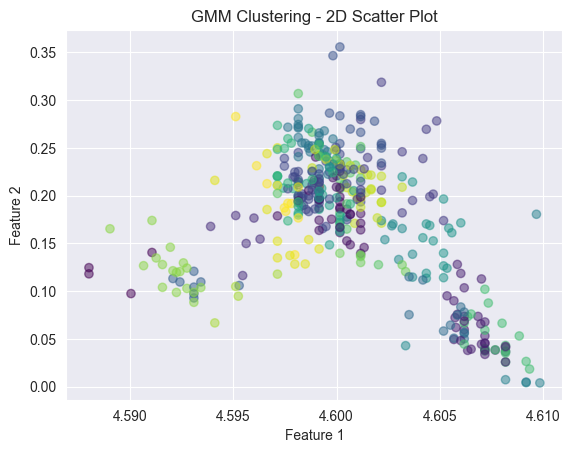

In [123]:
scaler = FunctionTransformer(np.log1p, validate=True)
df_scaled = scaler.fit_transform(df)

# Anzahl der Komponenten (Cluster) für GMM
n_components = 24  # Aus dem vorherigen Durchlauf wurde 24 gewählt

# Erstellen und Anpassen des Gaussian Mixture Models
gmm = GaussianMixture(n_components=n_components, random_state=0)
gmm.fit(df_scaled)

# Vorhersage des Clusters für jeden Datenpunkt
clusters = gmm.predict(df_scaled)

# Anzahl der Punkte in jedem Cluster zählen (Stahl-Kategorien)
cluster_counts = np.bincount(clusters)

# Cluster nach Größe sortieren
cluster_counts = sorted(cluster_counts, reverse=True)
print("Cluster Sizes:", cluster_counts)

# Visualisierung der Cluster im 2D-Streudiagramm
plt.scatter(df_scaled[:, 0], df_scaled[:, 1], c=clusters, cmap='viridis', alpha=0.5)
plt.title('GMM Clustering - 2D Scatter Plot')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.show()

Component 1: [4.58929397e+00 1.20135130e-01 5.98402834e-01 6.72119038e-01
 1.80694703e-02 4.46398495e-02 1.99523762e-02 5.54971766e-03
 7.73459129e-02 2.70026317e-02 1.72263602e-02 2.38183302e-01
 5.47815785e-03 2.56498283e-03 2.95227750e-03 3.92207132e-02
 1.48886125e-02 2.83195868e-02 2.29400066e-03 1.12436312e-03
 2.27240273e-03 4.52914386e-02 1.58958139e-02]
Component 2: [4.59996868e+00 1.85498648e-01 2.14813783e-01 4.69149822e-01
 2.16401155e-02 4.26859332e-02 9.46421688e-03 4.08506854e-03
 4.99954268e-02 4.46168163e-03 1.70980538e-02 1.68145525e-01
 3.11929460e-03 1.54015426e-03 2.19988796e-03 3.92207132e-02
 1.48886125e-02 1.42844265e-02 1.97947045e-03 1.24957774e-03
 2.12878084e-03 4.09542219e-02 1.64219609e-02]
Component 3: [4.60668731e+00 6.28476987e-02 4.98974463e-03 3.72813405e-01
 2.43394375e-02 2.68851782e-02 1.93619588e-02 3.58071622e-03
 3.14274766e-02 2.40138453e-03 1.38651304e-02 6.88530486e-02
 4.88497957e-03 1.22002100e-03 2.00464012e-03 3.92207132e-02
 1.48886125e-

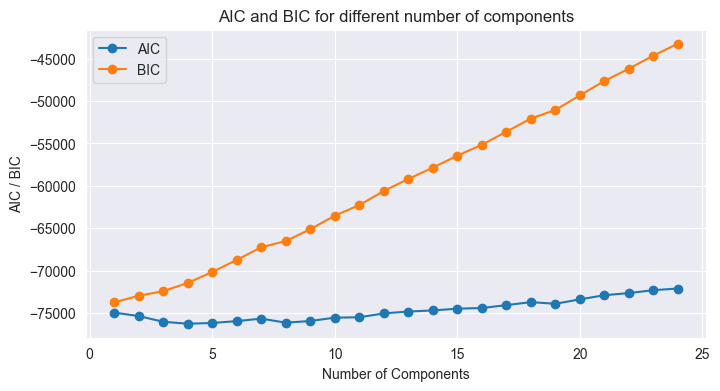

In [124]:
# Analyse der Hauptkomponenten
for i, component in enumerate(gmm.means_):
    print(f'Component {i+1}: {component}')

# Überprüfung der AIC- und BIC-Werte für verschiedene Anzahlen von Komponenten
n_components_range = range(1, 25)
aics = []
bics = []

for n_components in n_components_range:
    gmm = GaussianMixture(n_components=n_components, random_state=0)
    gmm.fit(df_scaled)
    aics.append(gmm.aic(df_scaled))
    bics.append(gmm.bic(df_scaled))

# Plot der AIC- und BIC-Werte
plt.figure(figsize=(8, 4))
plt.plot(n_components_range, aics, label='AIC', marker='o')
plt.plot(n_components_range, bics, label='BIC', marker='o')
plt.xlabel('Number of Components')
plt.ylabel('AIC / BIC')
plt.legend()
plt.title('AIC and BIC for different number of components')
plt.show()

# TestFall, (Ausreißer)

In [125]:
distances = gmm.predict_proba(df_scaled).min(axis=1)
threshold = np.percentile(distances, 95)  # Beispiel-Schwellenwert
outliers = df[distances > threshold]
print("Number of Outliers:", len(outliers))
print(outliers)

Number of Outliers: 0
Empty DataFrame
Columns: [Fe, C, Si, Mn, P, S, Cr, Mo, Ni, Al, Co, Cu, Nb, Ti, V, W, Pb, Sn, B, Ca, Zr, As, Bi]
Index: []

[0 rows x 23 columns]


Cluster Sizes: [111, 90, 81, 45, 27, 27, 20, 6]


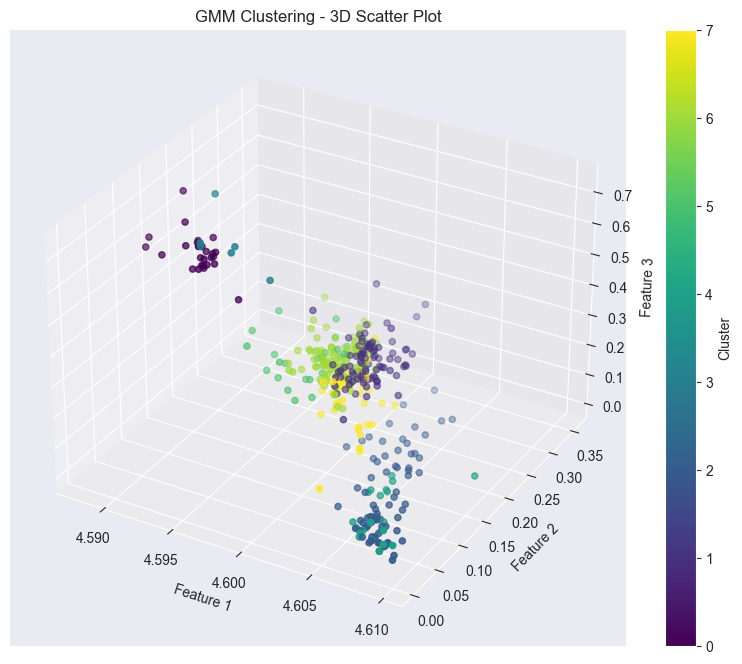

In [126]:
scaler = FunctionTransformer(np.log1p, validate=True)
df_scaled = scaler.fit_transform(df)

# Anzahl der Komponenten (Cluster) für GMM
n_components = 8

# Erstellen und Anpassen des Gaussian Mixture Models
gmm = GaussianMixture(n_components=n_components, random_state=0)
gmm.fit(df_scaled)

# Vorhersage des Clusters für jeden Datenpunkt
clusters = gmm.predict(df_scaled)

# Anzahl der Punkte in jedem Cluster zählen (Stahl-Kategorien)
cluster_counts = np.bincount(clusters)

# Cluster nach Größe sortieren
cluster_counts = sorted(cluster_counts, reverse=True)
print("Cluster Sizes:", cluster_counts)

# 3D-Plot für GMM Clustering erstellen
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')
scatter = ax.scatter(df_scaled[:, 0], df_scaled[:, 1], df_scaled[:, 2], c=clusters, cmap='viridis', marker='o')

ax.set_xlabel('Feature 1')
ax.set_ylabel('Feature 2')
ax.set_zlabel('Feature 3')
ax.set_title('GMM Clustering - 3D Scatter Plot')

# Farblegende hinzufügen
cbar = plt.colorbar(scatter)
cbar.set_label('Cluster')

plt.show()

# ClusterAnzahl Veranschaulichung

C:\Users\Mert\AppData\Local\Temp\ipykernel_27656\1856482249.py:28: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


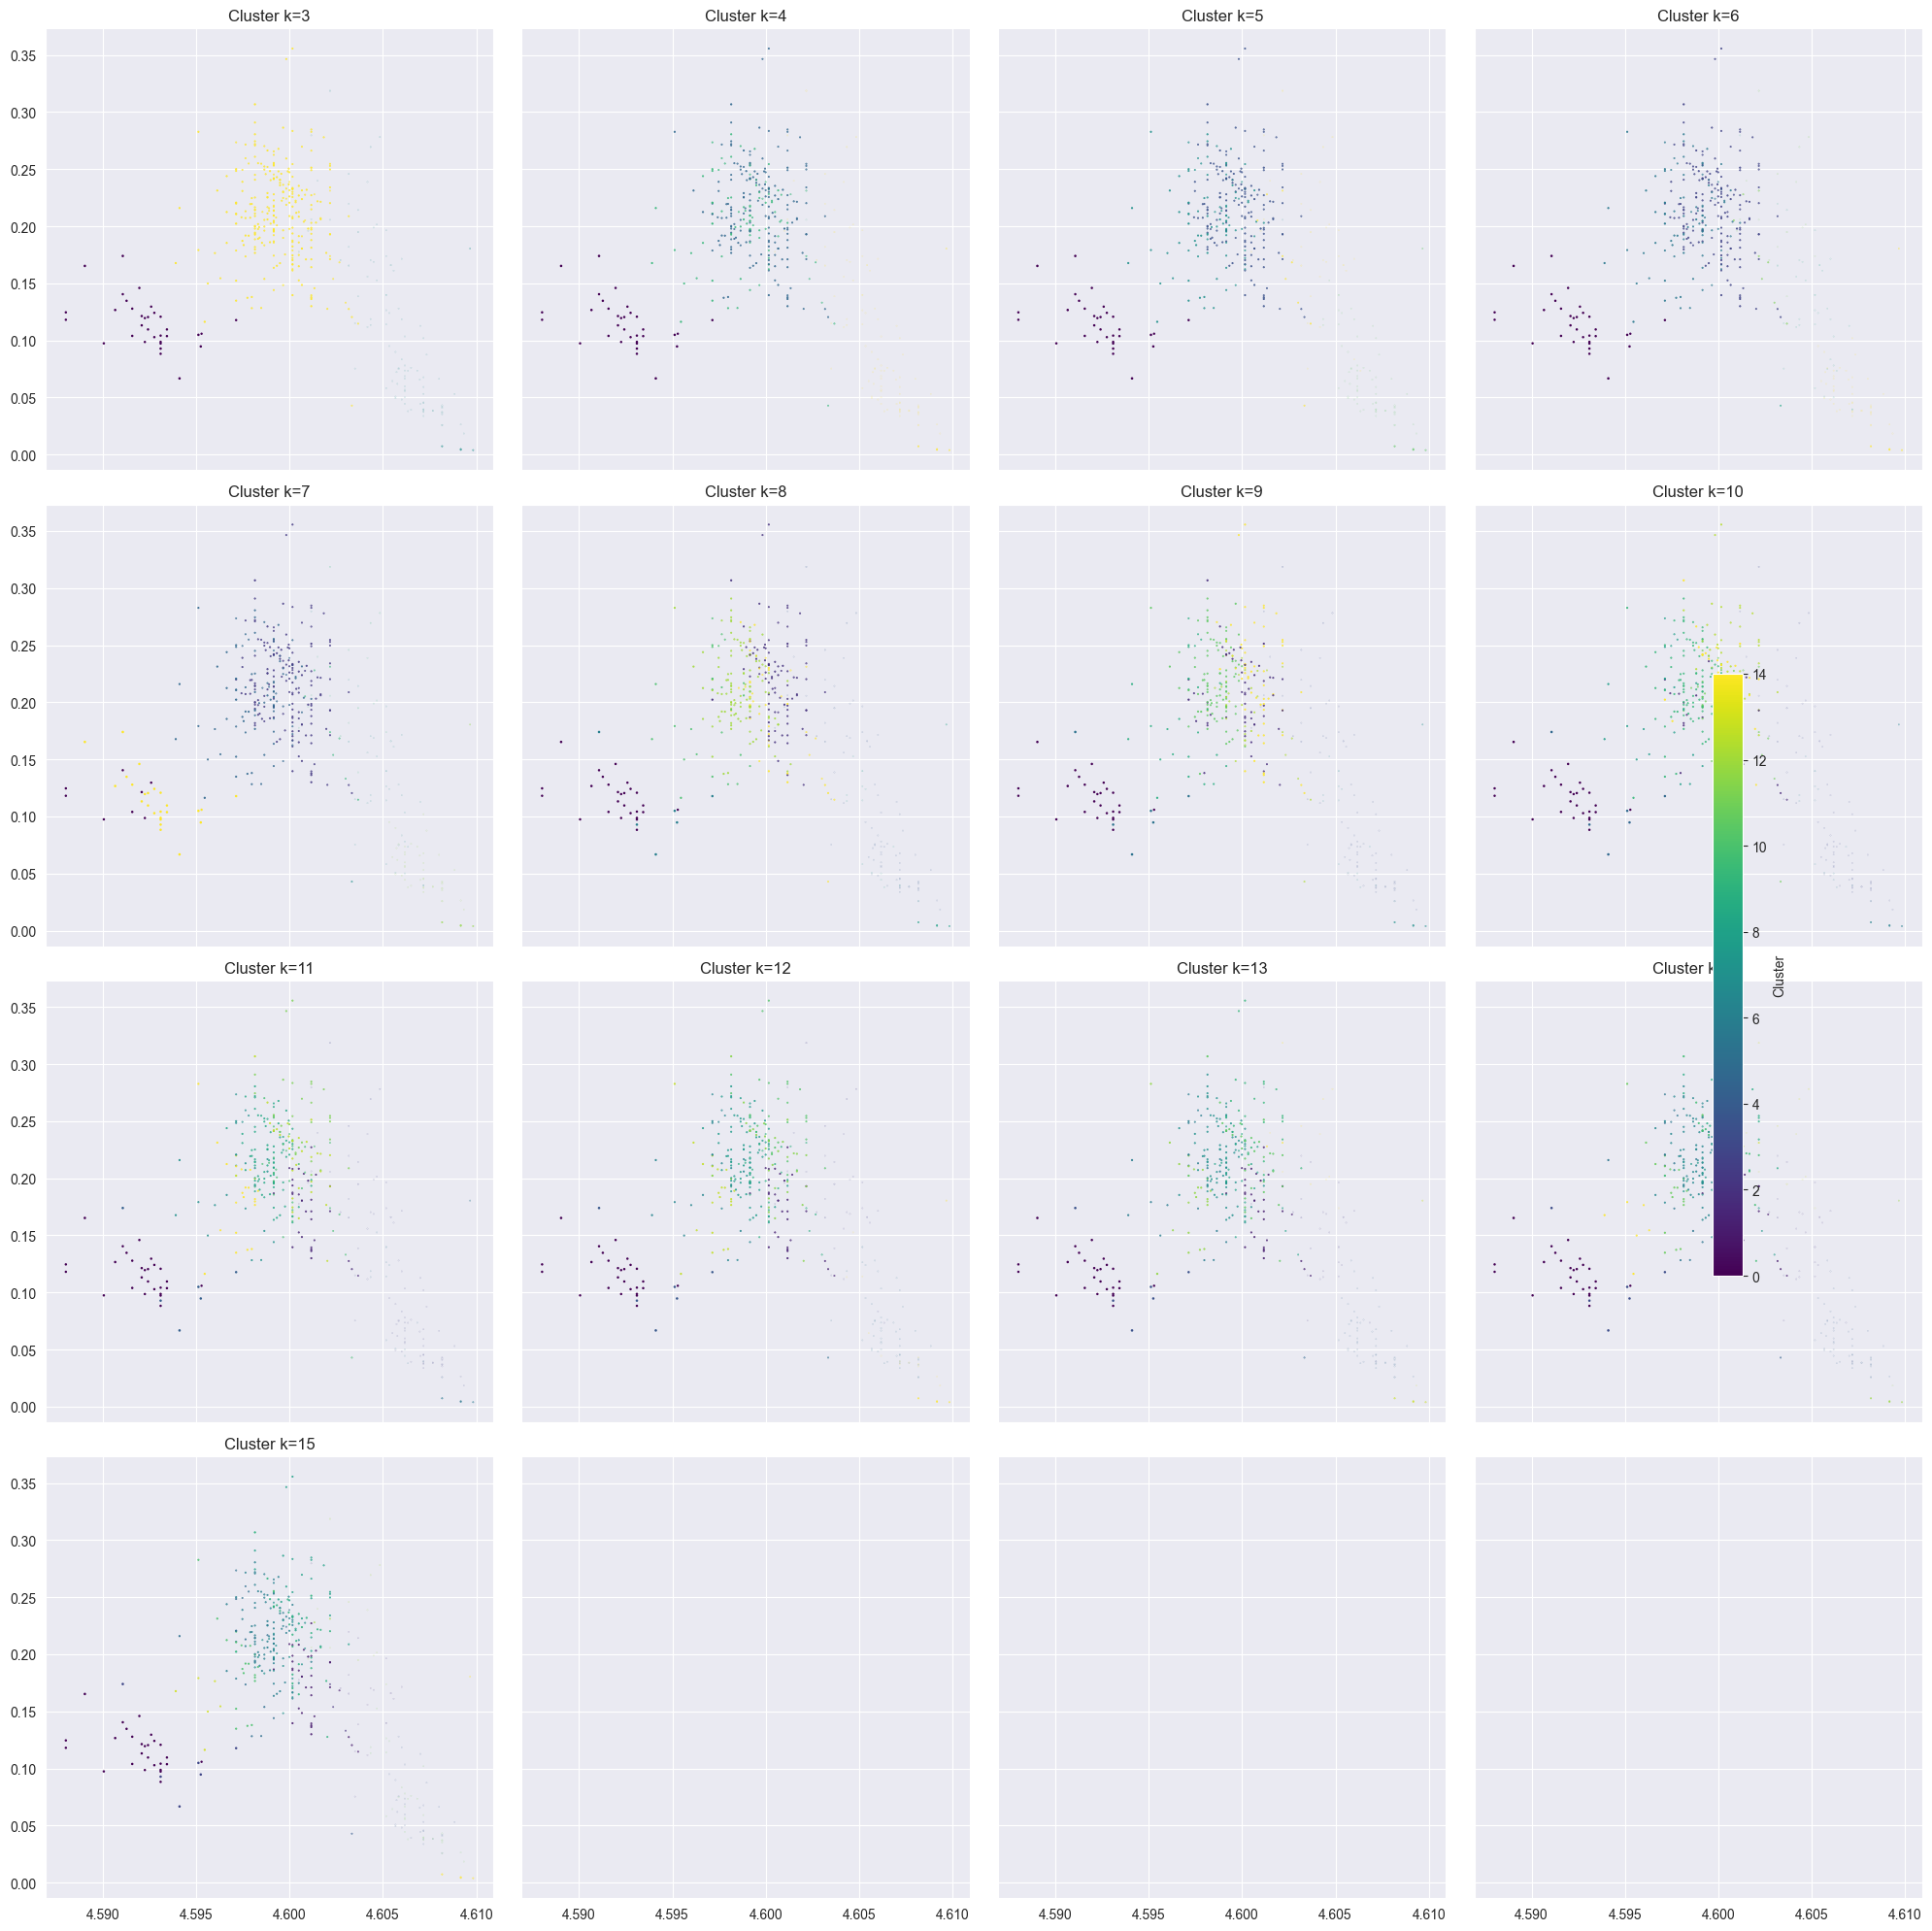

In [127]:
scaler = FunctionTransformer(np.log1p, validate=True)
df_scaled = scaler.fit_transform(df)

# Bereich der Anzahl der Komponenten (Cluster) für GMM
n_components_range = range(3, 16)

# Erstellen des Subplots für verschiedene Cluster
fig, axs = plt.subplots(4, 4, figsize=(20, 20), sharex=True, sharey=True)

for i, n_components in enumerate(n_components_range):
    # Erstellen und Anpassen des Gaussian Mixture Models
    gmm = GaussianMixture(n_components=n_components, random_state=0)
    gmm.fit(df_scaled)

    # Vorhersage des Clusters für jeden Datenpunkt
    clusters = gmm.predict(df_scaled)

    # 3D-Plot für GMM Clustering erstellen
    ax = axs[i // 4, i % 4]
    scatter = ax.scatter(df_scaled[:, 0], df_scaled[:, 1], df_scaled[:, 2], c=clusters, cmap='viridis', marker='o')

    ax.set_title(f'Cluster k={n_components}')

# Farblegende hinzufügen
cbar = plt.colorbar(scatter, ax=axs, orientation='vertical', fraction=0.02, pad=0.1)
cbar.set_label('Cluster')

plt.tight_layout()
plt.show()

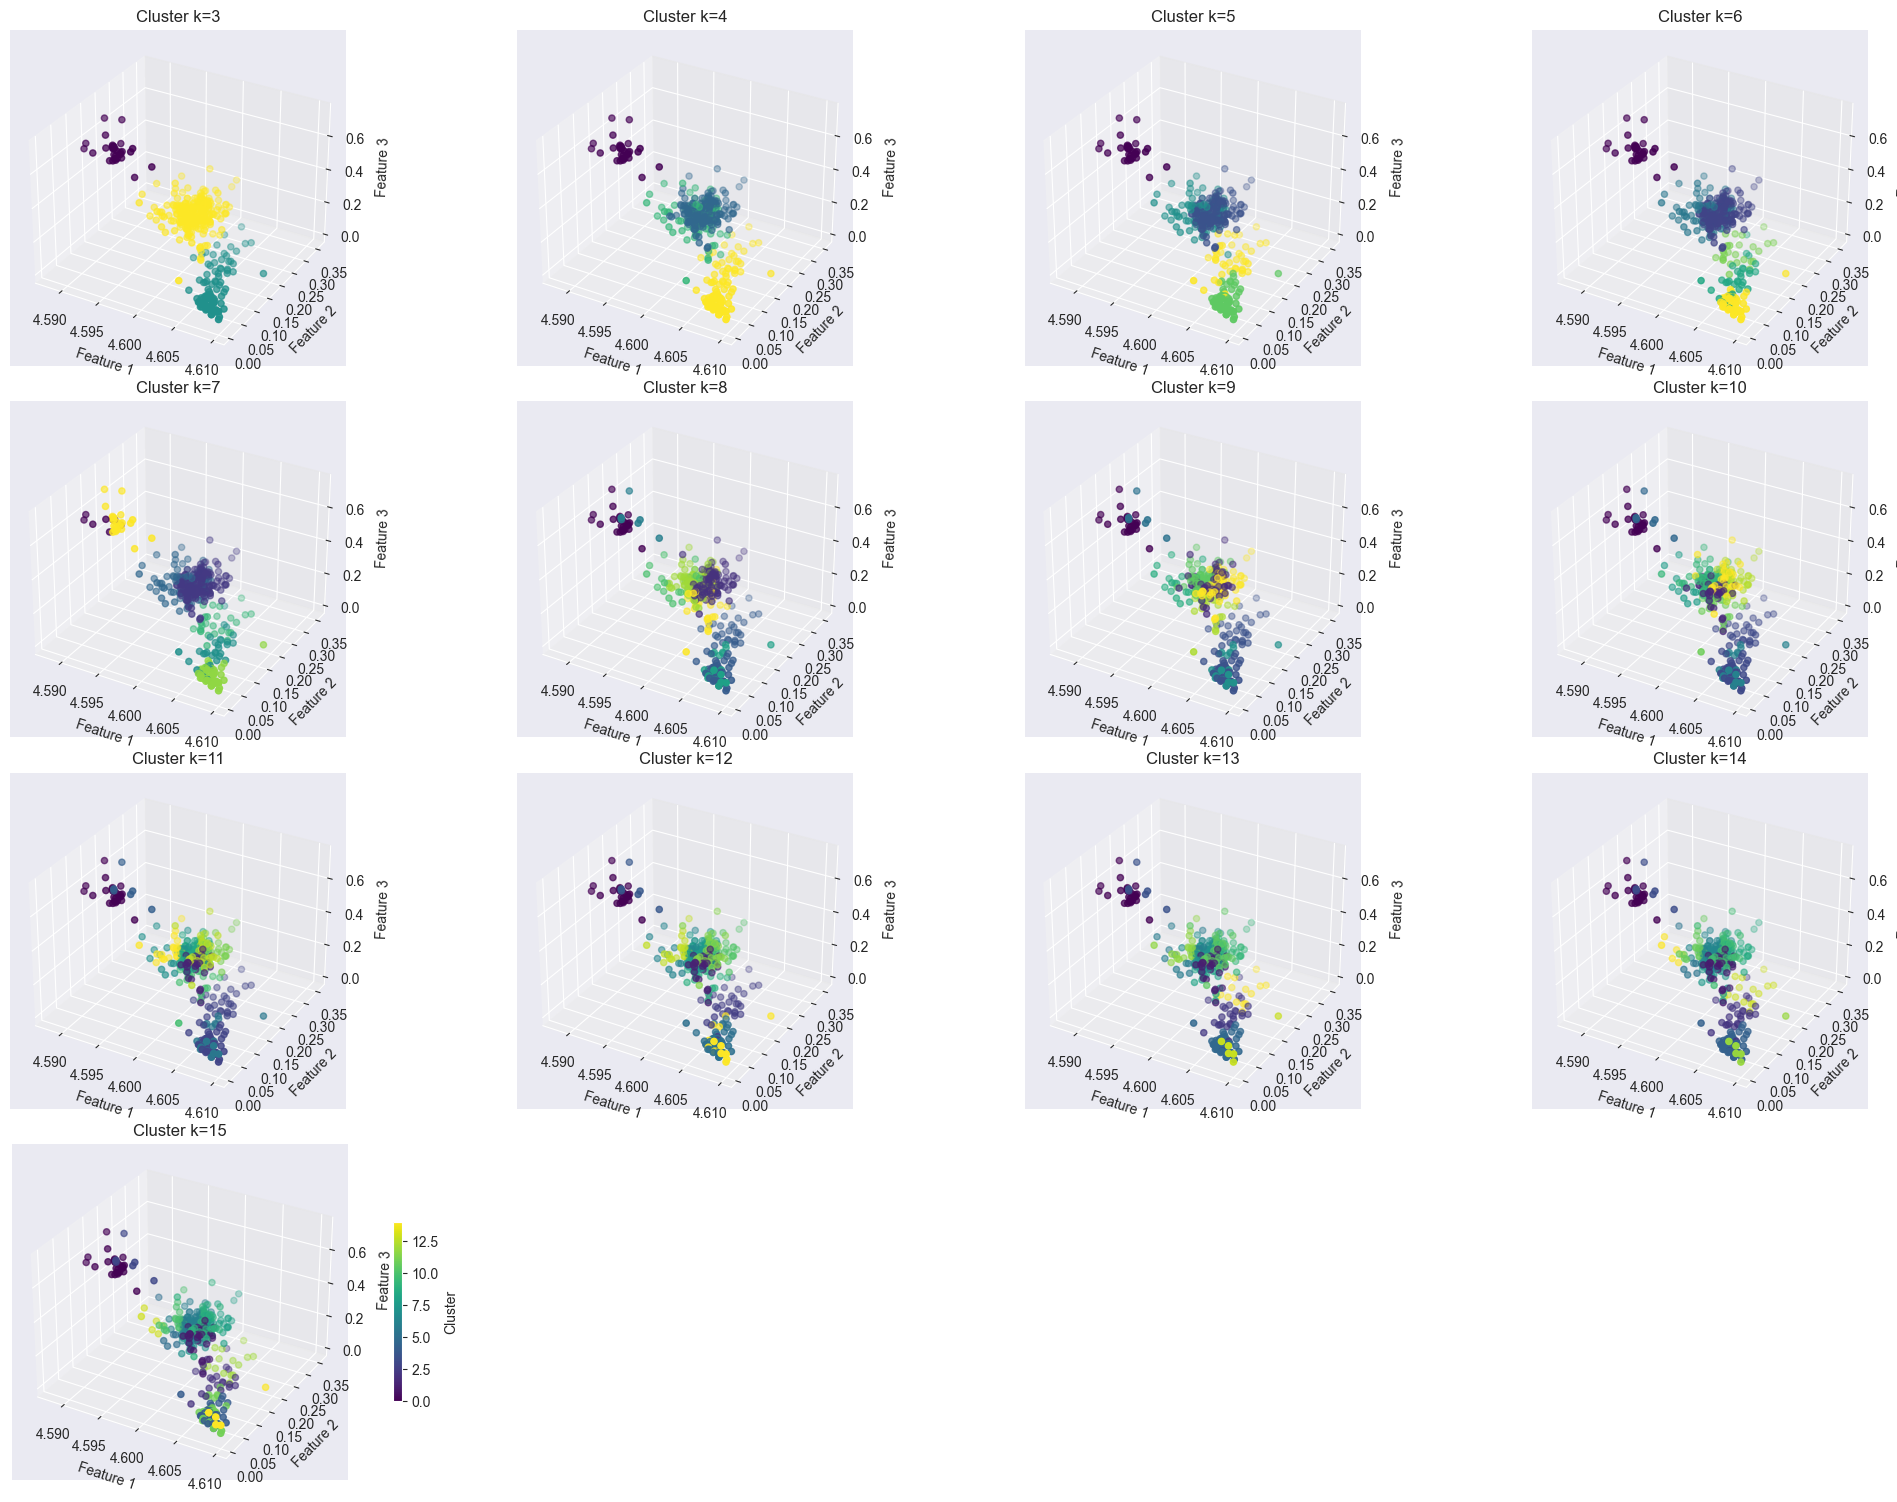

In [128]:
scaler = FunctionTransformer(np.log1p, validate=True)
df_scaled = scaler.fit_transform(df)

# Bereich der Anzahl der Komponenten (Cluster) für GMM
n_components_range = range(3, 16)

# Erstellen des Subplots für verschiedene Cluster
fig = plt.figure(figsize=(20, 15))

for i, n_components in enumerate(n_components_range):
    # Erstellen und Anpassen des Gaussian Mixture Models
    gmm = GaussianMixture(n_components=n_components, random_state=0)
    gmm.fit(df_scaled)

    # Vorhersage des Clusters für jeden Datenpunkt
    clusters = gmm.predict(df_scaled)

    # 3D-Plot für GMM Clustering erstellen
    ax = fig.add_subplot(4, 4, i + 1, projection='3d')
    scatter = ax.scatter(df_scaled[:, 0], df_scaled[:, 1], df_scaled[:, 2], c=clusters, cmap='viridis', marker='o')

    ax.set_title(f'Cluster k={n_components}')
    ax.set_xlabel('Feature 1')
    ax.set_ylabel('Feature 2')
    ax.set_zlabel('Feature 3')

# Farblegende hinzufügen
cbar = fig.colorbar(scatter, ax=ax, orientation='vertical', fraction=0.02, pad=0.1)
cbar.set_label('Cluster')

plt.tight_layout()
plt.show()

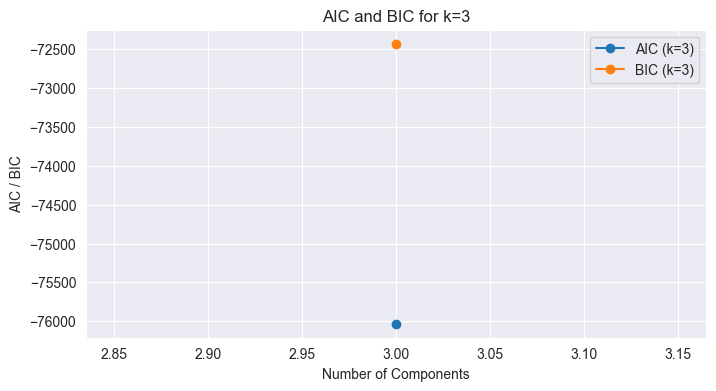

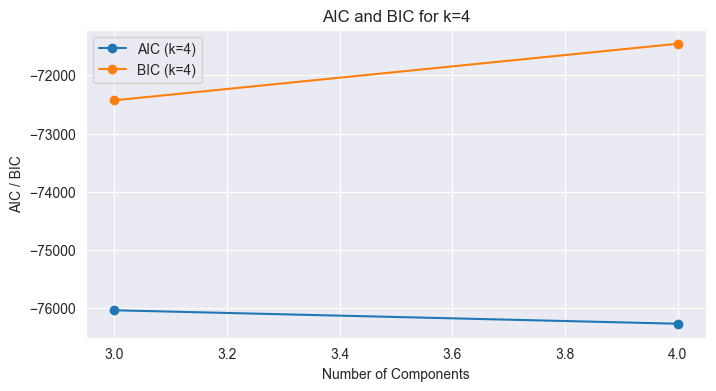

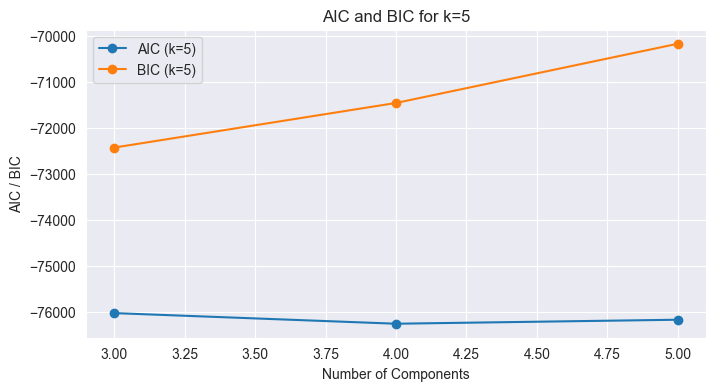

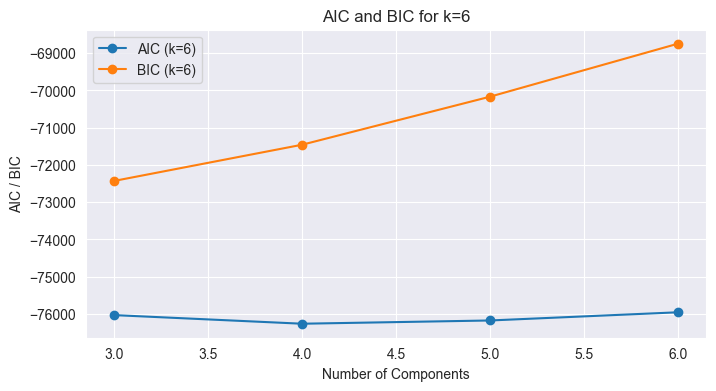

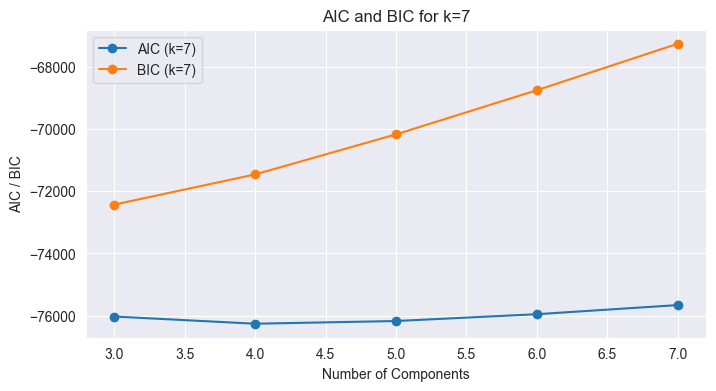

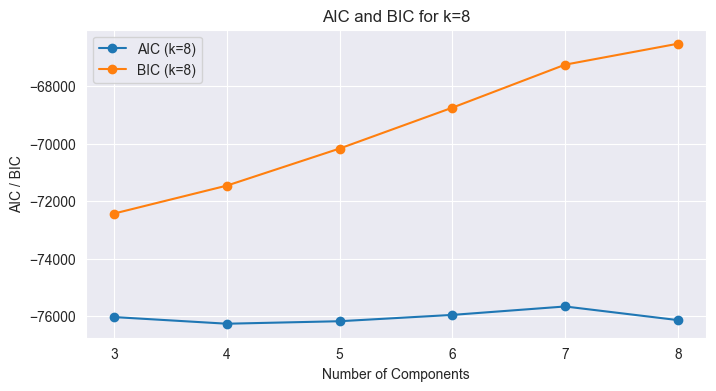

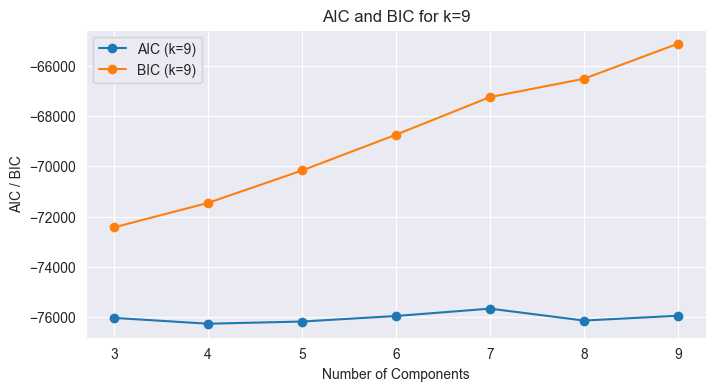

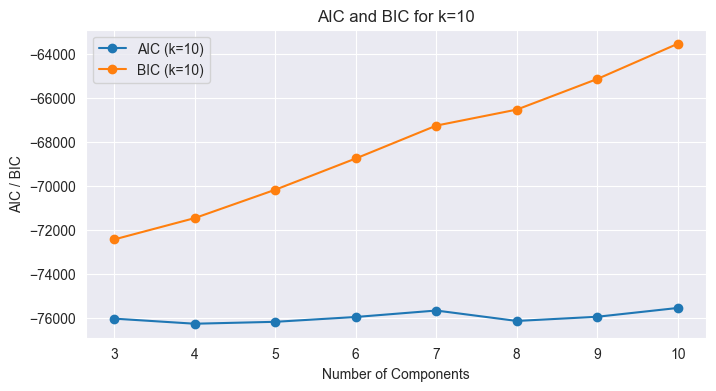

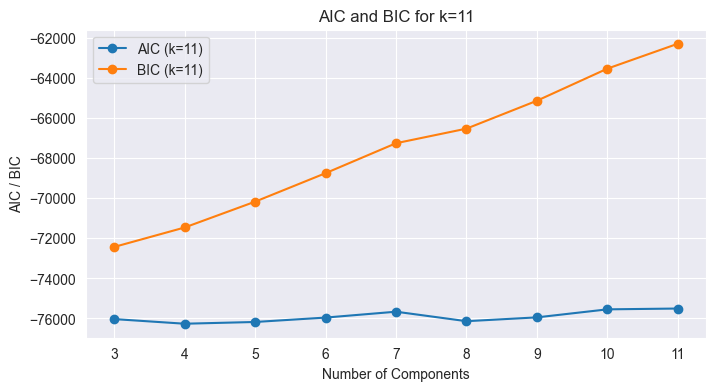

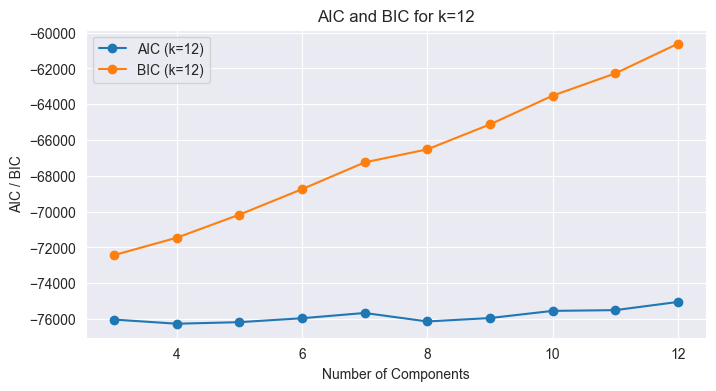

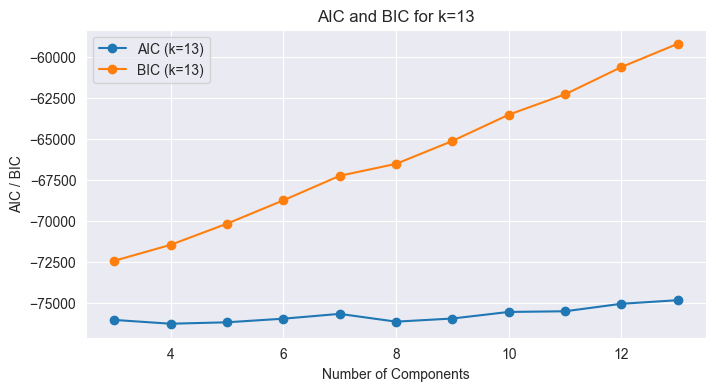

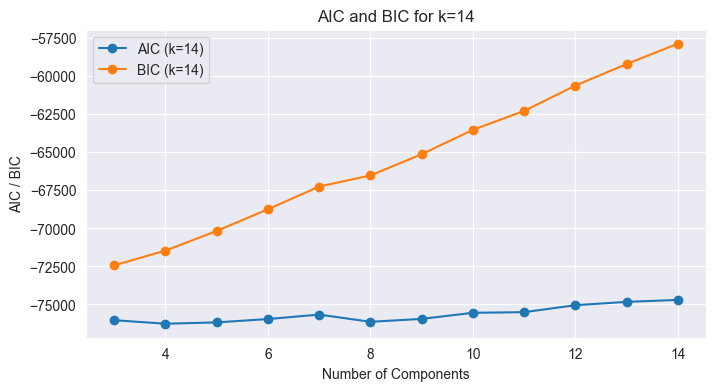

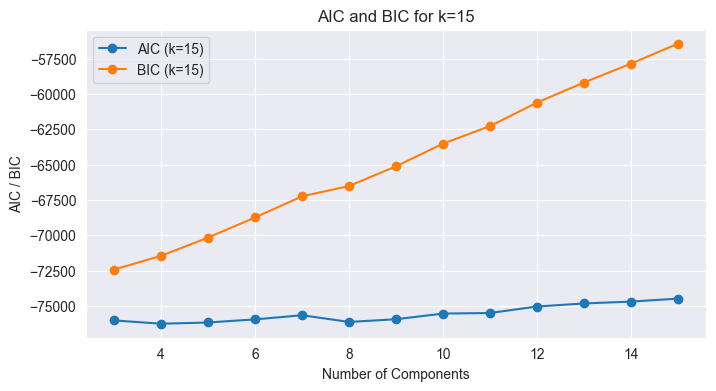

In [129]:
n_components_range = range(3, 16)  # Geändert auf k=3 bis k=15
aics = []
bics = []

for n_components in n_components_range:
    gmm = GaussianMixture(n_components=n_components, random_state=0)
    gmm.fit(df_scaled)
    aics.append(gmm.aic(df_scaled))
    bics.append(gmm.bic(df_scaled))

    # Plot der AIC- und BIC-Werte für jeden Wert von k
    plt.figure(figsize=(8, 4))
    plt.plot(range(3, n_components + 1), aics, label=f'AIC (k={n_components})', marker='o')
    plt.plot(range(3, n_components + 1), bics, label=f'BIC (k={n_components})', marker='o')
    plt.xlabel('Number of Components')
    plt.ylabel('AIC / BIC')
    plt.legend()
    plt.title(f'AIC and BIC for k={n_components}')
    plt.show()

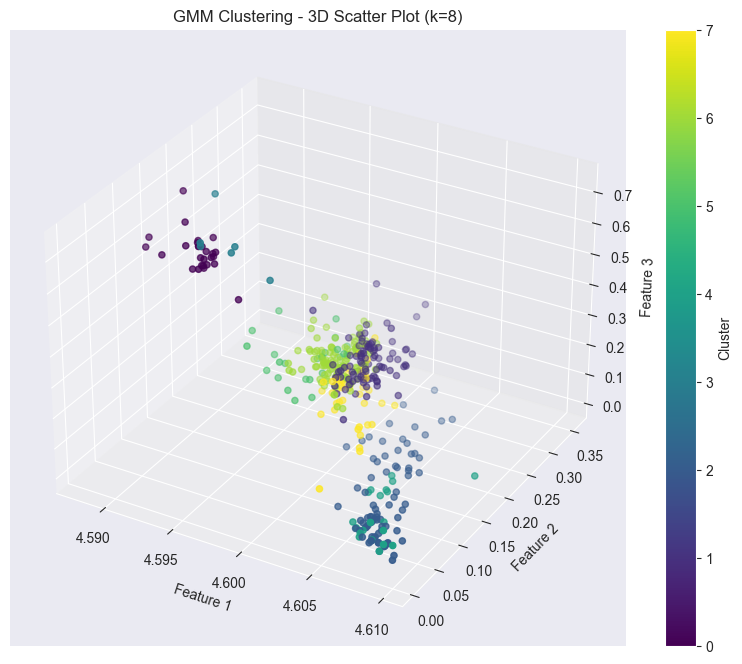

In [130]:
n_components_3d = 8
gmm_3d = GaussianMixture(n_components=n_components_3d, random_state=0)
gmm_3d.fit(df_scaled)

# Vorhersage des Clusters für jeden Datenpunkt
clusters_3d = gmm_3d.predict(df_scaled)

# Visualisierung der Cluster im 3D-Streudiagramm
fig_3d = plt.figure(figsize=(10, 8))
ax_3d = fig_3d.add_subplot(111, projection='3d')
scatter_3d = ax_3d.scatter(df_scaled[:, 0], df_scaled[:, 1], df_scaled[:, 2], c=clusters_3d, cmap='viridis', marker='o')

ax_3d.set_xlabel('Feature 1')
ax_3d.set_ylabel('Feature 2')
ax_3d.set_zlabel('Feature 3')
ax_3d.set_title(f'GMM Clustering - 3D Scatter Plot (k={n_components_3d})')

plt.colorbar(scatter_3d, ax=ax_3d, label='Cluster')
plt.show()

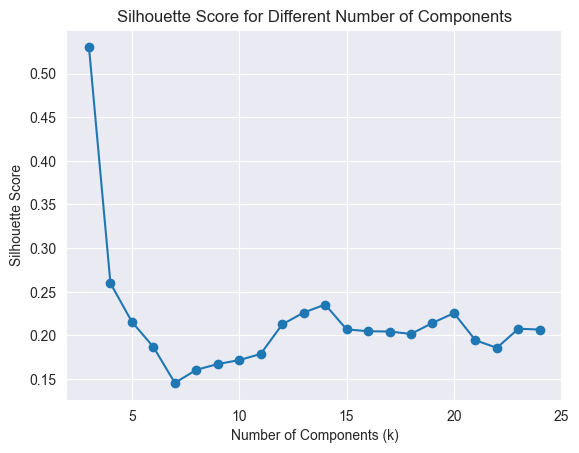

In [131]:
silhouette_scores = [] 

for k in range(3, 25):
    gmm_k = GaussianMixture(n_components=k, random_state=0)
    clusters_k = gmm_k.fit_predict(df_scaled)
    silhouette_scores.append(silhouette_score(df_scaled, clusters_k))

# Plot des Silhouette Scores für jeden Wert von k
plt.plot(range(3, 25), silhouette_scores, marker='o')
plt.xlabel('Number of Components (k)')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Score for Different Number of Components')
plt.show()

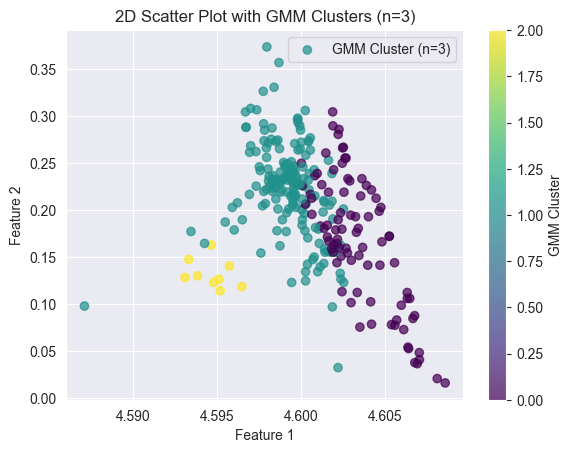

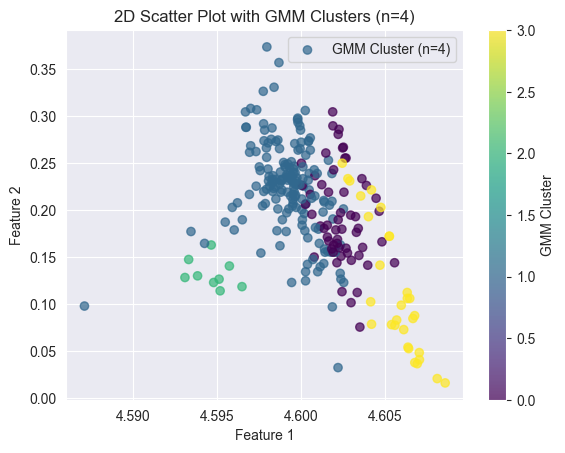

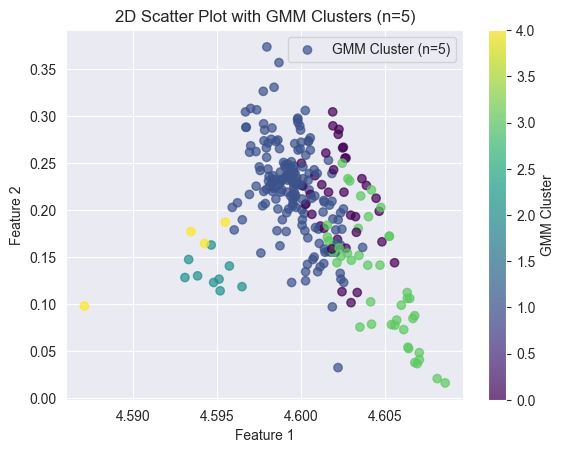

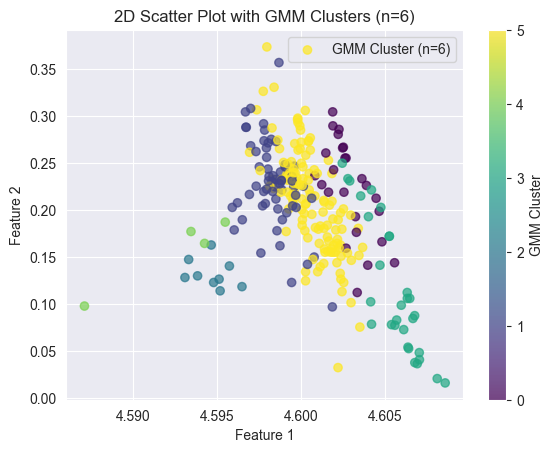

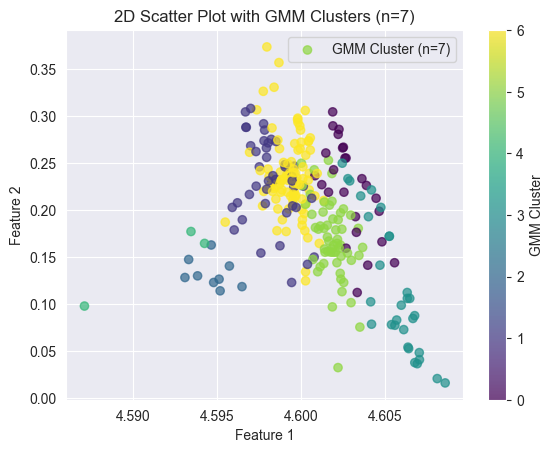

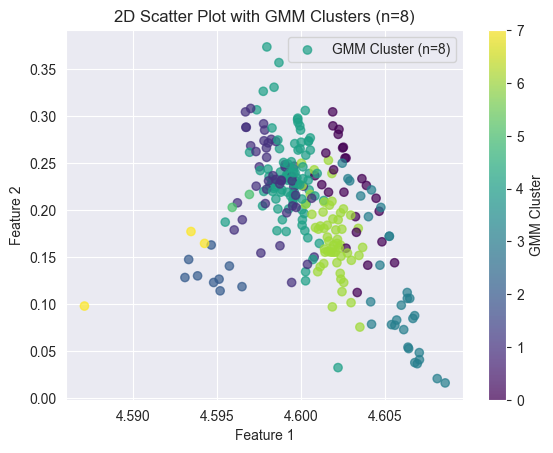

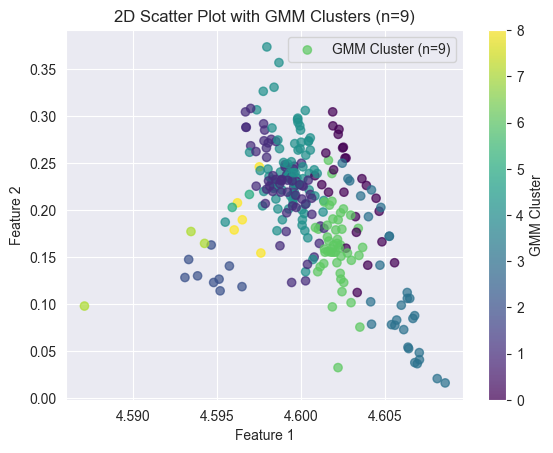

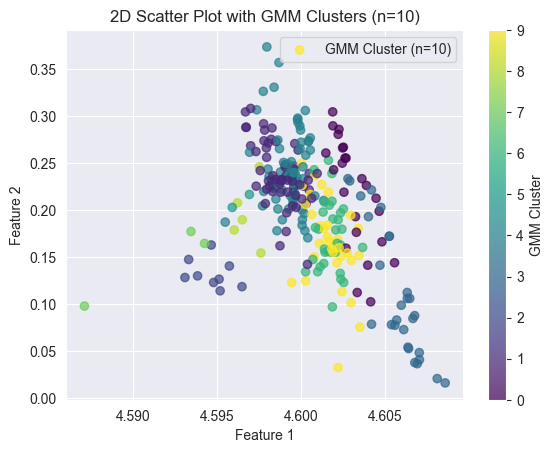

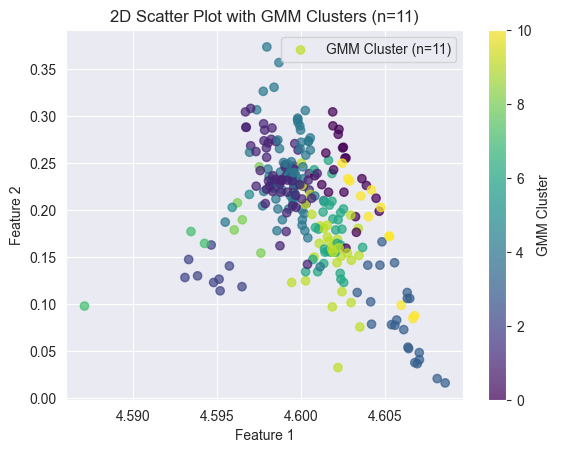

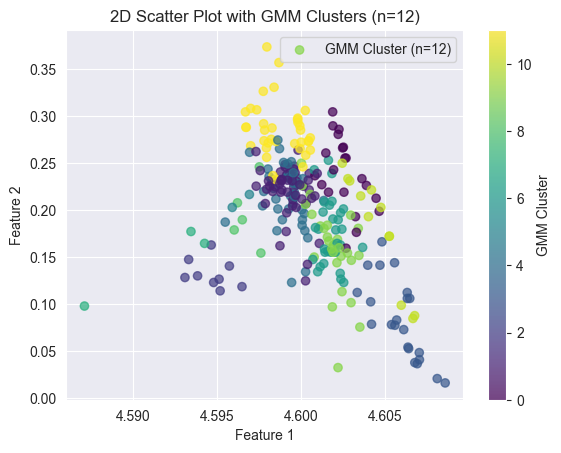

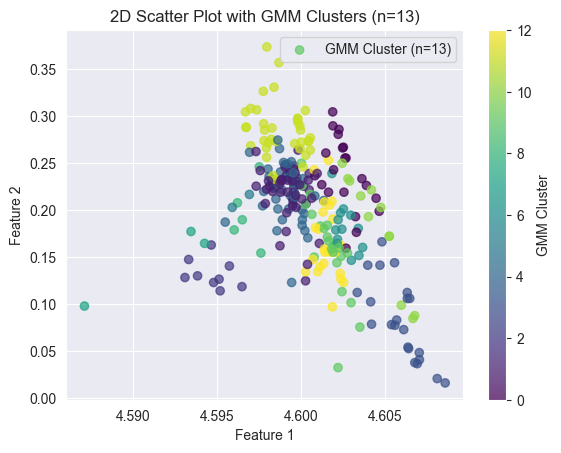

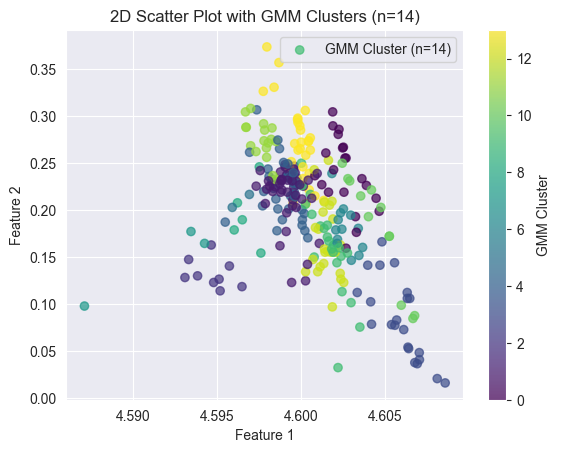

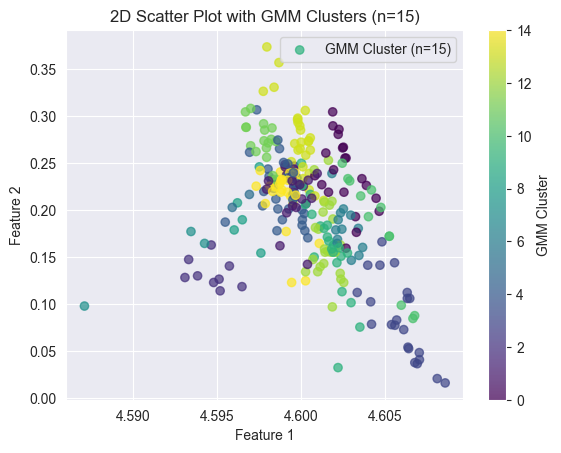

In [132]:

columns_to_scale = ['Fe', 'C', 'Si', 'Mn', 'P', 'S', 'Cr', 'Mo', 'Ni', 'Al', 'Co', 'Cu', 'Nb', 'Ti', 'V', 'W', 'Pb', 'Sn', 'B', 'Ca', 'Zr', 'As', 'Bi']
scaler = FunctionTransformer(np.log1p, validate=True)
scaled_data = scaler.fit_transform(df_test[columns_to_scale])
df_scaled = pd.DataFrame(scaled_data, columns=columns_to_scale)

# Beispiel für GMM-Clustering
n_components_list = list(range(3, 16))

for n_components_gmm in n_components_list:
    gmm = GaussianMixture(n_components=n_components_gmm, random_state=0)
    clusters_gmm = gmm.fit_predict(df_scaled)
    df_test['GMM_Cluster'] = clusters_gmm

    # 2D Scatter Plot mit Steel Classes und GMM-Clustering
    plt.scatter(df_scaled.iloc[:, 0], df_scaled.iloc[:, 1], c=df_test['GMM_Cluster'], cmap='viridis', alpha=0.7, label=f'GMM Cluster (n={n_components_gmm})')
    plt.title(f'2D Scatter Plot with GMM Clusters (n={n_components_gmm})')
    plt.xlabel('Feature 1')
    plt.ylabel('Feature 2')
    plt.legend()
    plt.colorbar(label='GMM Cluster')
    plt.show()

          C        Si        Mn         P         S        Cr        Ni  \
0  0.289667  0.204833  0.530167  0.024883  0.044583  0.034917  0.049383   
1  0.097283  0.975000  0.674667  0.026433  0.034617  0.009183  0.042583   
2  0.132667  0.834167  0.899667  0.014850  0.047567  0.023467  0.112167   
3  0.125333  0.792167  0.959333  0.014950  0.046583  0.029950  0.112667   
4  0.235143  0.238571  0.729143  0.027686  0.042086  0.014886  0.049871   

         Al        Cu  
0  0.002083  0.144333  
1  0.003133  0.198000  
2  0.054733  0.365667  
3  0.050267  0.367000  
4  0.004214  0.166571  


C:\Users\Mert\OneDrive\Desktop\FoPra\venv\lib\site-packages\sklearn\base.py:458: UserWarning: X has feature names, but FunctionTransformer was fitted without feature names
  warnings.warn(


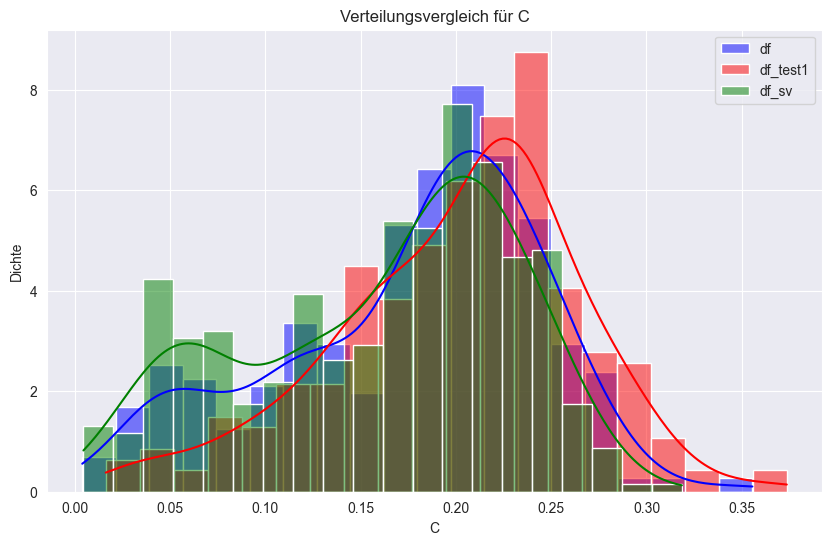

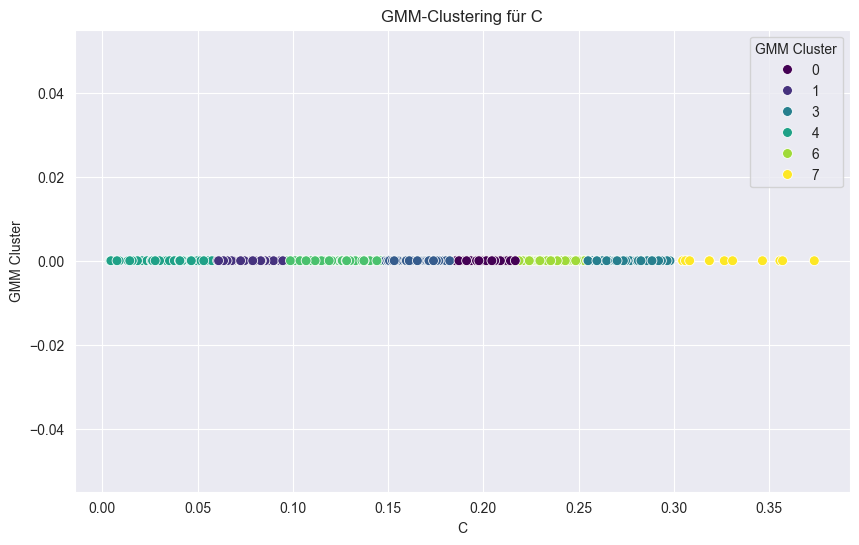

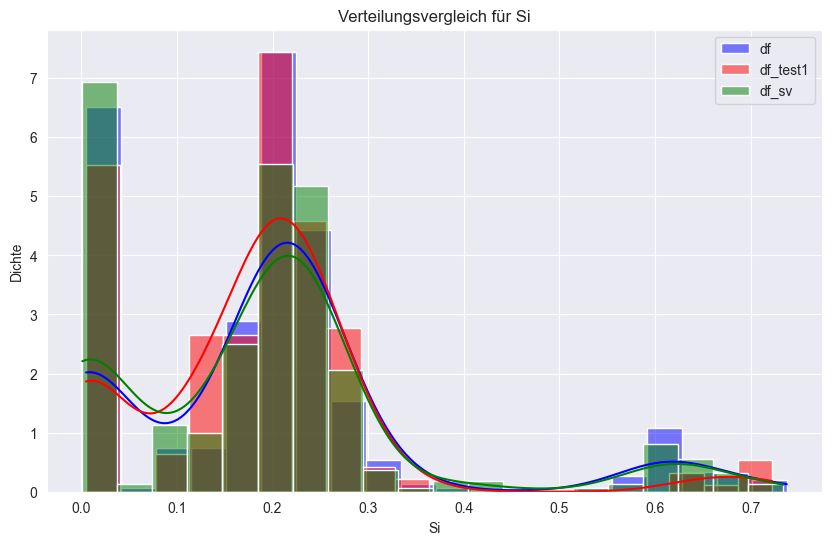

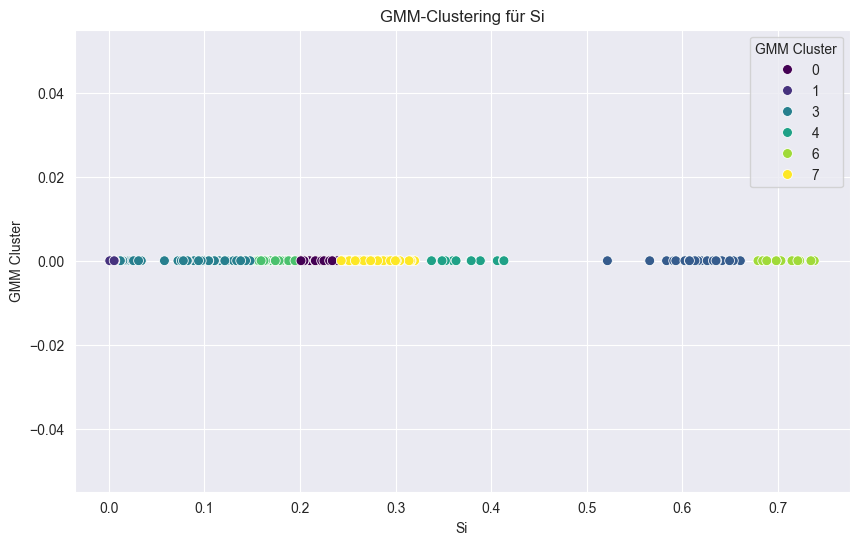

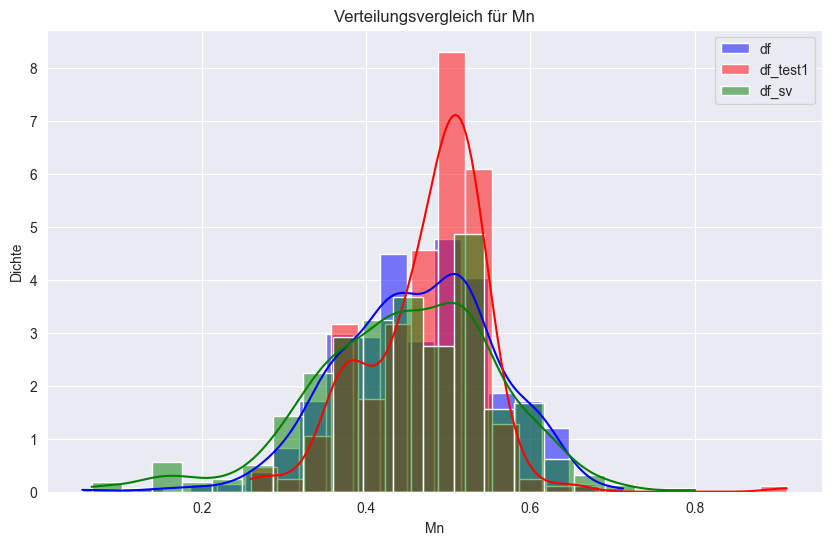

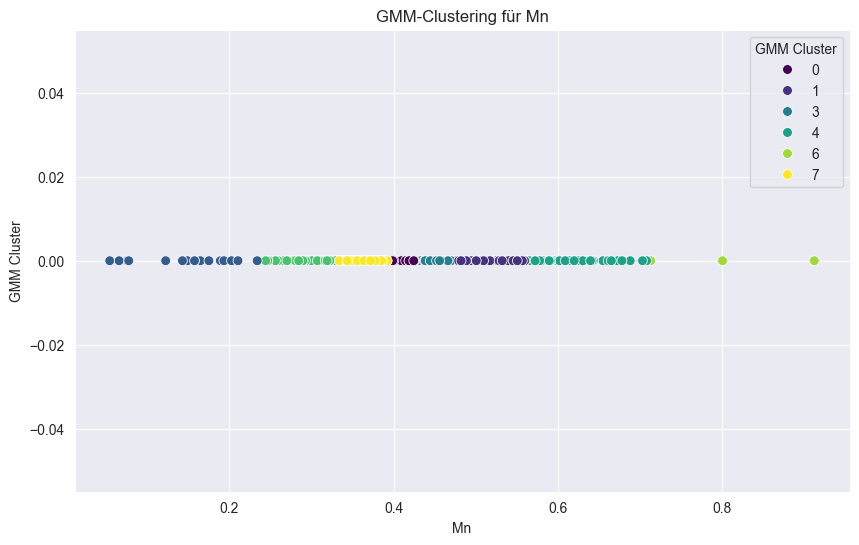

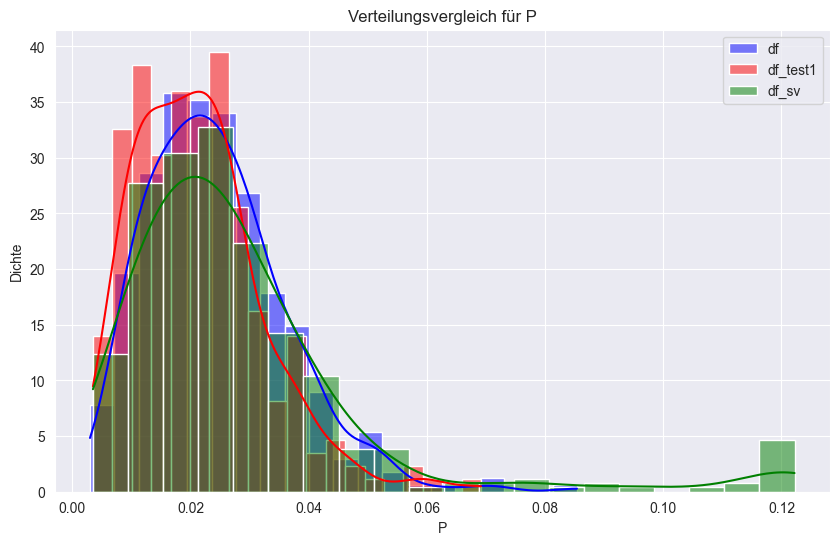

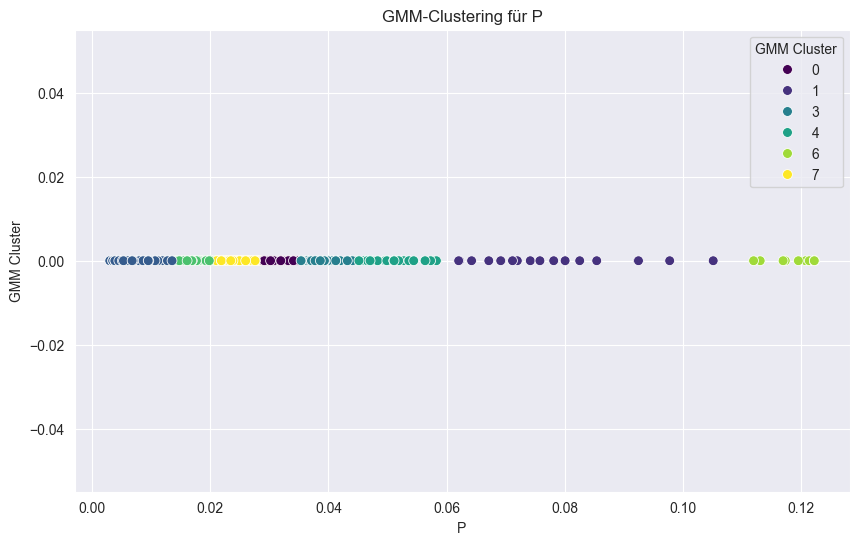

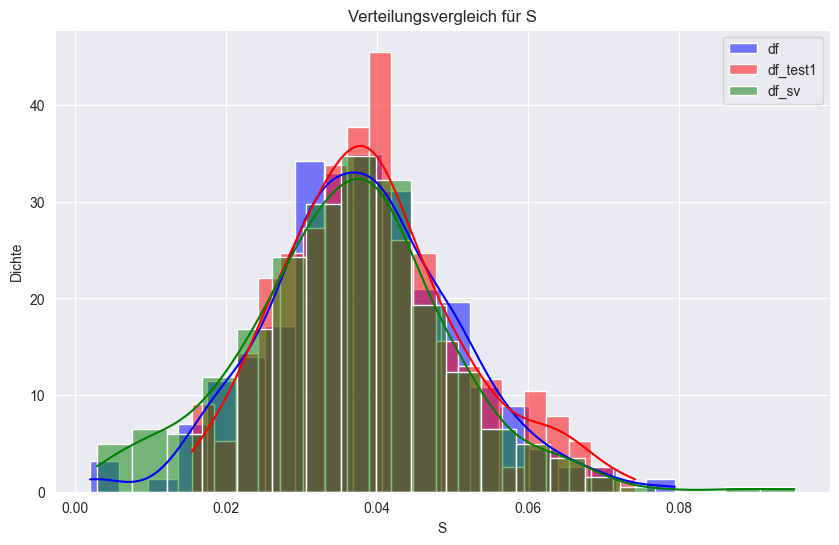

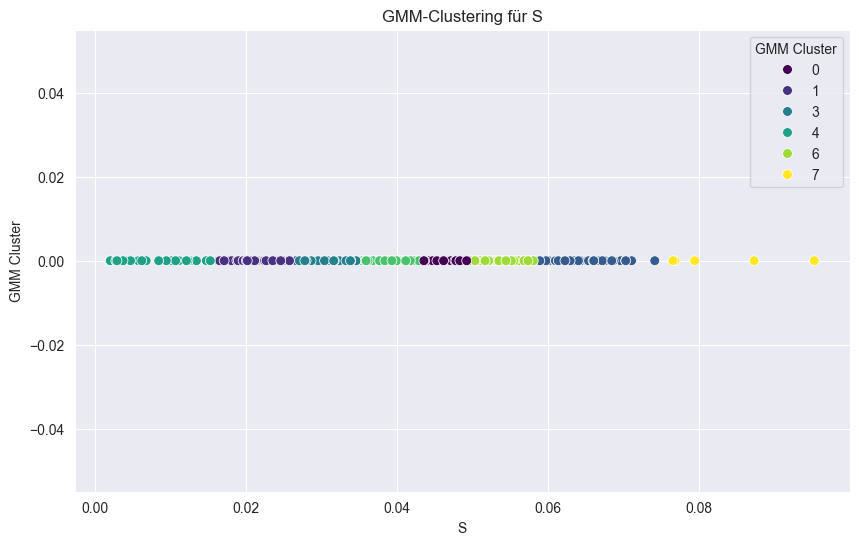

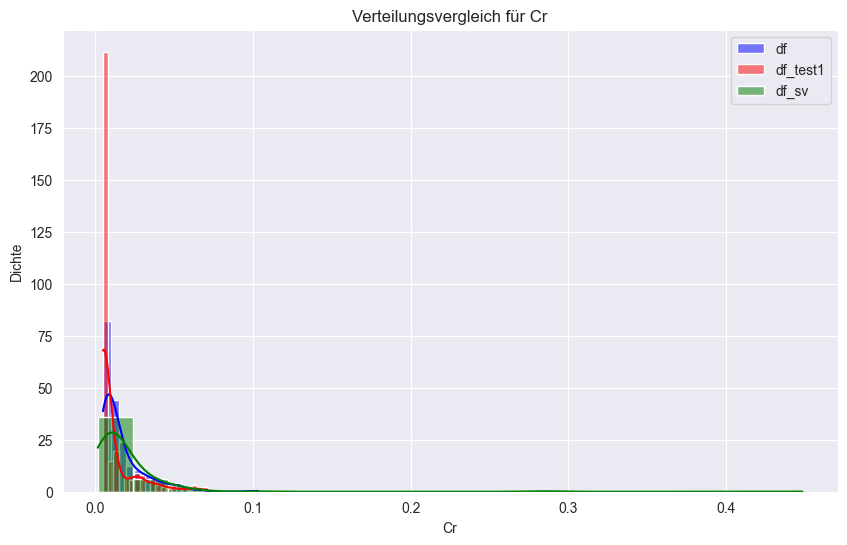

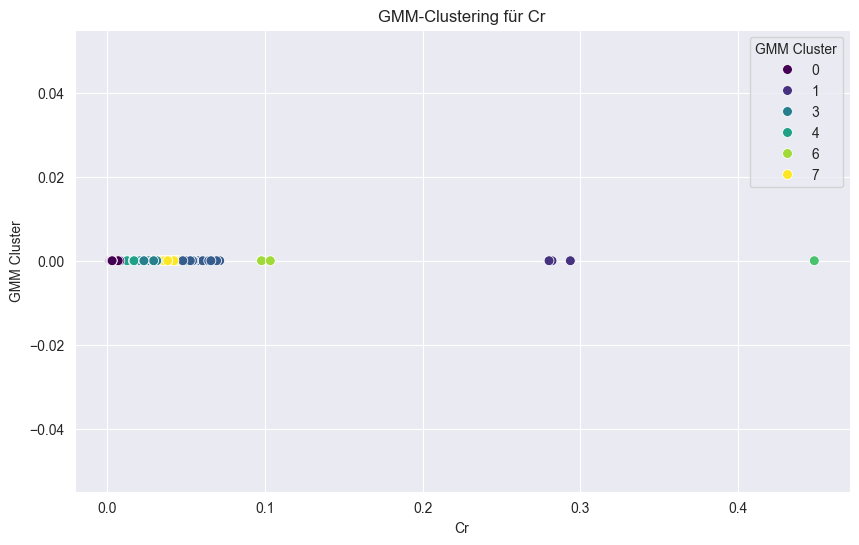

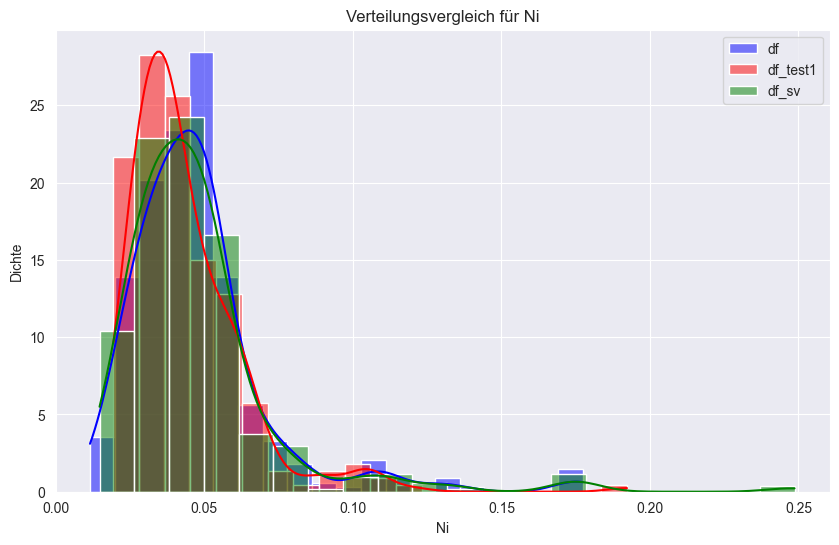

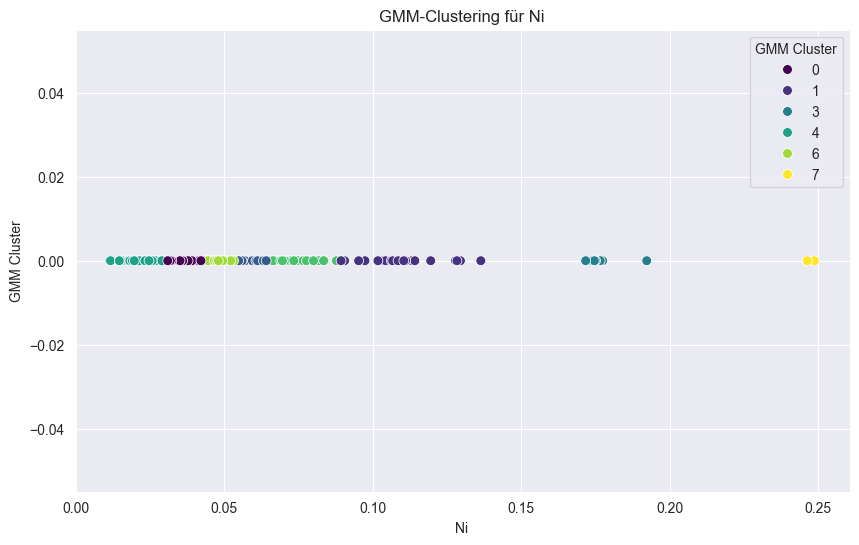

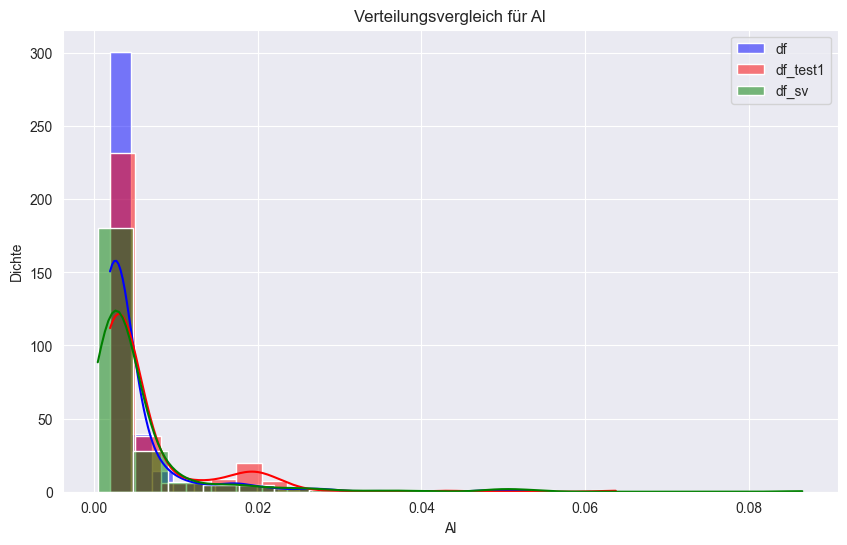

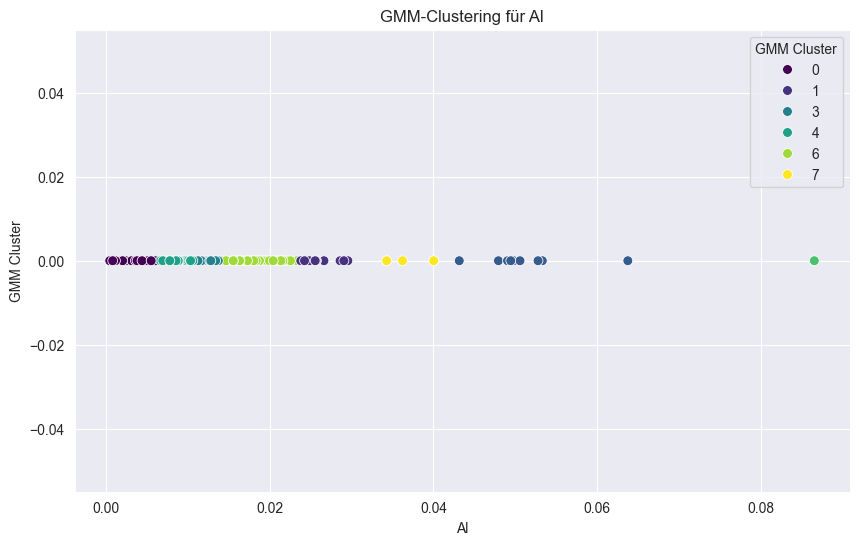

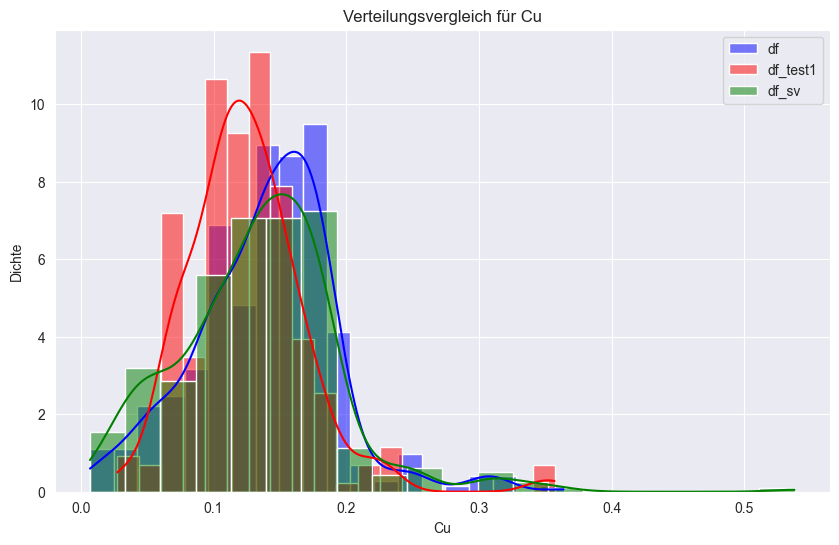

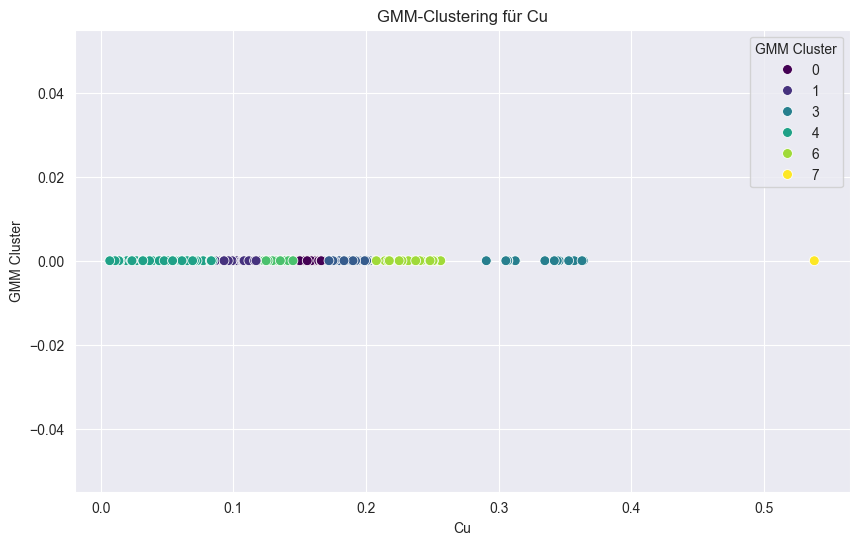

In [133]:
df_sv = pd.read_csv('C:/Users/Mert/OneDrive/Desktop/FoPra/data/cleaned data/labeled_OES_data.csv')
df_sv = df_sv.drop(columns=['steel_class'])
df_sv = df_sv.apply(lambda x: x.str.replace(',', '.').astype(float) if x.name != 'Material' else x)
print(df_sv.head())

# Standardisierung der Daten mit log1p-Transformation
scaler = FunctionTransformer(np.log1p, validate=True)
df_sv_scaled_array = scaler.transform(df_sv)
df_scaled_array = scaler.fit_transform(df)
df_test1_scaled_array = scaler.transform(df_test1)

# Umwandlung der skalierten Arrays zurück in DataFrames
df_scaled = pd.DataFrame(df_scaled_array, columns=df.columns)
df_test1_scaled = pd.DataFrame(df_test1_scaled_array, columns=df_test1.columns)
df_sv_scaled = pd.DataFrame(df_sv_scaled_array, columns=df_sv.columns)

# Spalten, die verglichen werden sollen(Optional mehr)
columns_to_compare = ['C','Si','Mn','P','S','Cr','Ni','Al','Cu']

# Erstellen der Diagramme für jede Spalte
for column in columns_to_compare:
    plt.figure(figsize=(10, 6))

    # Histogramm für df
    sns.histplot(df_scaled[column], color="blue", label='df', kde=True, stat="density", bins=20)

    # Histogramm für df_test1
    sns.histplot(df_test1_scaled[column], color="red", label='df_test1', kde=True, stat="density", bins=20)
    
    # Histogramm für df_sv
    sns.histplot(df_sv_scaled[column], color="green", label='df_sv', kde=True, stat="density", bins=20)

    # Legende und Titel hinzufügen
    plt.legend()
    plt.title(f'Verteilungsvergleich für {column}')
    plt.xlabel(column)
    plt.ylabel('Dichte')

   
    plt.show()

    # GMM-Clustering für die verglichenen Spalten
    n_components_gmm = 8 
    gmm = GaussianMixture(n_components=n_components_gmm, random_state=0)
    df_combined = pd.concat([df_scaled[[column]], df_test1_scaled[[column]], df_sv_scaled[[column]]], ignore_index=True)
    clusters_gmm = gmm.fit_predict(df_combined)

    # Visualisierung der GMM-Cluster
    plt.figure(figsize=(10, 6))
    sns.scatterplot(x=df_combined[column], y=np.zeros_like(df_combined[column]), hue=clusters_gmm, palette='viridis', s=50)
    plt.title(f'GMM-Clustering für {column}')
    plt.xlabel(column)
    plt.ylabel('GMM Cluster')
    plt.legend(title='GMM Cluster', loc='upper right')
    plt.show()